In [ ]:
%pip install -q datasets transformers ftfy scikit-learn

## Imports, configuration and reproducibility

In [ ]:
import os
import time
import sys
import random
import hashlib
import platform
import ftfy
import copy
from pathlib import Path
from collections import Counter
from importlib import metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from datasets import (
    load_dataset,
    Dataset,
    DatasetDict,
    Features,
    Value,
    ClassLabel,
    Image as HFImage
)
from huggingface_hub import snapshot_download
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoTokenizer
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)
from sklearn.preprocessing import StandardScaler
import joblib
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)


# Project directory
PROJECT_DIR = Path("/content/CrisisMMD_Project")
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "images"
FEATURE_DIR = PROJECT_DIR / "features"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
LOG_DIR = PROJECT_DIR / "logs"
for directory in [
    DATA_DIR, IMAGE_DIR, FEATURE_DIR,
    CHECKPOINT_DIR, RESULTS_DIR, LOG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
# Environment information
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "seed": SEED
}
print("ENVIRONMENT INFORMATION")
display(
    pd.DataFrame(
        environment.items(),
        columns=["Setting", "Value"]
    )
)
print("Setup completed successfully.")
print("Project directory:", PROJECT_DIR)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

ENVIRONMENT INFORMATION


,Setting,Value
0,python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
1,platform,Linux-6.6.159+-x86_64-with-glibc2.39
2,pytorch,2.14.1+cu130
3,cuda_available,True
4,gpu,Tesla T4
5,seed,42


Setup completed successfully.
Project directory: /content/CrisisMMD_Project
Device: cuda
GPU: Tesla T4


## Load and inspect the dataset

In [ ]:
# Dataset configuration
DATASET_NAME = "QCRI/CrisisMMD"
DATASET_CONFIG = "informative"
# Load dataset
dataset = load_dataset(
    DATASET_NAME,
    DATASET_CONFIG
)
print("Dataset loaded successfully.")
print("\nDataset structure:")
print(dataset)
# Expected split sizes
EXPECTED_SPLITS = {
    "train": 13608,
    "dev": 2237,
    "test": 2237
}
# Verify split sizes
print("\nDATASET SPLIT VERIFICATION")
for split_name, expected_size in EXPECTED_SPLITS.items():
    actual_size = len(dataset[split_name])
    print(f"\n{split_name.upper()}")
    print("Expected records:", expected_size)
    print("Actual records:", actual_size)
    assert actual_size == expected_size, (
        f"Unexpected record count in {split_name}"
    )
total_records = sum(
    len(dataset[split_name])
    for split_name in dataset.keys()
)
assert total_records == 18082
print("\nTotal records:", total_records)
print("All dataset splits verified successfully.")
# Inspect dataset columns
print("\nDATASET COLUMNS")
print(dataset["train"].column_names)
# Inspect feature information
print("\nDATASET FEATURES")
print(dataset["train"].features)
# Extract label mappings
ID_TO_LABEL = dict(
    enumerate(dataset["train"].features["label"].names)
)
LABEL_TO_ID = {
    label: idx
    for idx, label in ID_TO_LABEL.items()
}
print("\nLABEL MAPPING")
print(ID_TO_LABEL)
# Class distribution across each split
print("\nLABEL DISTRIBUTION")
for split_name in dataset.keys():
    label_counts = Counter(dataset[split_name]["label"])
    print(f"\n{split_name.upper()}")
    for label_id, label_name in ID_TO_LABEL.items():
        print(
            f"{label_name}: "
            f"{label_counts.get(label_id, 0)}"
        )
# Inspect one sample without decoding its image
sample = dataset["train"][0]
print("\nSAMPLE RECORD")
print("Event:", sample["event_name"])
print("Tweet ID:", sample["tweet_id"])
print("Image ID:", sample["image_id"])
print("Text:", sample["tweet_text"])
print("Label:", ID_TO_LABEL[sample["label"]])
print("Image path:", sample["image_path"])

Dataset loaded successfully.

Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 13608
    })
    dev: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
    test: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
})

DATASET SPLIT VERIFICATION

TRAIN
Expected records: 13608
Actual records: 13608

DEV
Expected records: 2237
Actual records: 2237

TEST
Expected records: 2237
Actual records: 2237

Total records: 18082
All dataset splits verified successfully.

DATASET COLUMNS
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']

DATASET FEATURES
{'event_name': Value('string'), 'tweet_id': Value('string'), 'image_id': Value('string'), 'tweet_text': Val

## Dataset quality and exploratory analysis

In [ ]:
# Convert dataset splits to DataFrames
# Exclude the image column to avoid loading images into memory.
dataframes = {
    split_name: dataset[split_name]
    .remove_columns(["image"])
    .to_pandas()
    for split_name in dataset.keys()
}
# DATASET OVERVIEW
print("DATASET OVERVIEW")
overview = pd.DataFrame([
    {
        "Split": split_name,
        "Records": len(df),
        "Columns": len(df.columns),
        "Unique tweets": df["tweet_id"].nunique(),
        "Unique images": df["image_id"].nunique()
    }
    for split_name, df in dataframes.items()
])
display(overview)
# MISSING VALUES
print("\nMISSING VALUE ANALYSIS")
missing_results = []
for split_name, df in dataframes.items():
    for column in df.columns:
        missing = df[column].isna().sum()
        if df[column].dtype == "object":
            missing += (
                df[column]
                .astype("string")
                .str.strip()
                .eq("")
                .sum()
            )
        missing_results.append({
            "Split": split_name,
            "Column": column,
            "Missing values": int(missing)
        })
missing_df = pd.DataFrame(missing_results)
display(missing_df)
# DUPLICATE ANALYSIS
print("\nDUPLICATE ANALYSIS")
duplicate_results = []
for split_name, df in dataframes.items():
    exact_duplicates = df.duplicated(
        subset=df.columns.tolist()
    ).sum()
    repeated_text = df.duplicated(
        subset=["tweet_text"],
        keep=False
    ).sum()
    duplicate_results.append({
        "Split": split_name,
        "Exact duplicate rows": exact_duplicates,
        "Records with repeated text": repeated_text,
        "Unique tweets": df["tweet_id"].nunique()
    })
duplicate_df = pd.DataFrame(duplicate_results)
display(duplicate_df)
# LABEL DISTRIBUTION
print("\nLABEL DISTRIBUTION")
label_results = []
for split_name, df in dataframes.items():
    counts = df["label"].value_counts()
    for label_id, label_name in ID_TO_LABEL.items():
        count = counts.get(label_id, 0)
        label_results.append({
            "Split": split_name,
            "Label": label_name,
            "Count": count,
            "Percentage": round(
                count / len(df) * 100, 2
            )
        })
label_distribution_df = pd.DataFrame(label_results)
display(label_distribution_df)
# DISASTER EVENT DISTRIBUTION
print("\nDISASTER EVENT DISTRIBUTION")
event_distribution_df = (
    pd.concat(dataframes.values())
    ["event_name"]
    .value_counts()
    .rename_axis("Disaster event")
    .reset_index(name="Records")
)
event_distribution_df["Percentage"] = (
    event_distribution_df["Records"]
    / 18082 * 100
).round(2)
display(event_distribution_df)
# TEXT LENGTH ANALYSIS
print("\nTEXT LENGTH ANALYSIS")
text_results = []
for split_name, df in dataframes.items():
    text_lengths = (
        df["tweet_text"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )
    text_results.append({
        "Split": split_name,
        "Average words": round(text_lengths.mean(), 2),
        "Median words": text_lengths.median(),
        "Maximum words": text_lengths.max(),
        "Minimum words": text_lengths.min()
    })
text_length_df = pd.DataFrame(text_results)
display(text_length_df)
# CHECK CROSS-SPLIT OVERLAP
print("\nCROSS-SPLIT OVERLAP CHECK")
for column in ["tweet_id", "image_id", "image_path"]:
    train_values = set(dataframes["train"][column].astype(str))
    dev_values = set(dataframes["dev"][column].astype(str))
    test_values = set(dataframes["test"][column].astype(str))
    train_dev = len(train_values & dev_values)
    train_test = len(train_values & test_values)
    dev_test = len(dev_values & test_values)
    print(f"\n{column}")
    print("Train-Dev overlap:", train_dev)
    print("Train-Test overlap:", train_test)
    print("Dev-Test overlap:", dev_test)
print("\nExploratory data analysis completed.")

DATASET OVERVIEW


,Split,Records,Columns,Unique tweets,Unique images
0,train,13608,6,11584,13608
1,dev,2237,6,2237,2237
2,test,2237,6,2237,2237



MISSING VALUE ANALYSIS


,Split,Column,Missing values
0,train,event_name,0
1,train,tweet_id,0
2,train,image_id,0
3,train,tweet_text,0
4,train,image_path,0
5,train,label,0
6,dev,event_name,0
7,dev,tweet_id,0
8,dev,image_id,0
9,dev,tweet_text,0



DUPLICATE ANALYSIS


,Split,Exact duplicate rows,Records with repeated text,Unique tweets
0,train,0,3169,11584
1,dev,0,0,2237
2,test,0,0,2237


... (3 outputs left out)

,Disaster event,Records,Percentage
0,hurricane_maria,4556,25.20
1,hurricane_irma,4504,24.91
2,hurricane_harvey,4434,24.52
3,california_wildfires,1589,8.79
4,mexico_earthquake,1380,7.63
5,srilanka_floods,1022,5.65
6,iraq_iran_earthquake,597,3.30



TEXT LENGTH ANALYSIS


,Split,Average words,Median words,Maximum words,Minimum words
0,train,13.83,14.0,26,3
1,dev,13.76,14.0,26,4
2,test,13.71,14.0,25,4



CROSS-SPLIT OVERLAP CHECK

tweet_id
Train-Dev overlap: 0
Train-Test overlap: 0
Dev-Test overlap: 0

image_id
Train-Dev overlap: 0
Train-Test overlap: 0
Dev-Test overlap: 0

image_path
Train-Dev overlap: 0
Train-Test overlap: 0
Dev-Test overlap: 0

Exploratory data analysis completed.


In [ ]:
# Check repeated text across dataset splits

def normalise_text(text):
    return " ".join(str(text).casefold().split())

split_texts = {
    split: set(
        df["tweet_text"].map(normalise_text)
    )
    for split, df in dataframes.items()
}

print("CROSS-SPLIT TEXT OVERLAP")

for split_a, split_b in [
    ("train", "dev"),
    ("train", "test"),
    ("dev", "test")
]:
    overlap = split_texts[split_a] & split_texts[split_b]

    print(f"{split_a} - {split_b}: {len(overlap)}")

CROSS-SPLIT TEXT OVERLAP
train - dev: 0
train - test: 0
dev - test: 0


## Image Downloading and Quality Assessment

In [ ]:
# Download dataset images from Hugging Face
DATASET_SNAPSHOT_DIR = Path(
    snapshot_download(
        repo_id=DATASET_NAME,
        repo_type="dataset",
        allow_patterns=["data_image/**"],
        local_dir=str(DATA_DIR / "qcri_dataset")
    )
)
IMAGE_DIRECTORY = DATASET_SNAPSHOT_DIR / "data_image"
print("Image download completed.")
print("Image directory:", IMAGE_DIRECTORY)
print("Directory exists:", IMAGE_DIRECTORY.exists())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18082 files:   0%|          | 0/18082 [00:00<?, ?it/s]

Image download completed.
Image directory: /content/CrisisMMD_Project/data/qcri_dataset/data_image
Directory exists: True


In [ ]:
# Check image availability and quality
image_audit = []
missing_images = []
corrupt_images = []
for split_name in dataset.keys():
    print(f"\nChecking {split_name} images...")
    for relative_path in tqdm(dataset[split_name]["image_path"]):
        image_path = DATASET_SNAPSHOT_DIR / relative_path
        if not image_path.is_file():
            missing_images.append(str(image_path))
            continue
        try:
            # Verify file integrity
            with Image.open(image_path) as img:
                img.verify()
            # Read image properties
            with Image.open(image_path) as img:
                img.load()
                # Check whether the image contains transparent pixels
                rgba = img.convert("RGBA")
                has_transparent_pixels = (
                    rgba.getchannel("A").getextrema()[0] < 255
                )
                image_audit.append({
                    "split": split_name,
                    "image_path": relative_path,
                    "format": img.format,
                    "mode": img.mode,
                    "width": img.width,
                    "height": img.height,
                    "transparent_pixels": has_transparent_pixels
                })
        except Exception as error:
            corrupt_images.append({
                "image_path": str(image_path),
                "error": str(error)
            })
# Convert audit results into DataFrames
image_audit_df = pd.DataFrame(image_audit)
corrupt_images_df = pd.DataFrame(corrupt_images)
print("\nIMAGE QUALITY SUMMARY")
print("Expected images:", sum(len(dataset[s]) for s in dataset))
print("Successfully verified:", len(image_audit_df))
print("Missing images:", len(missing_images))
print("Corrupt images:", len(corrupt_images))
print("\nIMAGE FORMAT DISTRIBUTION")
display(
    image_audit_df["format"]
    .value_counts()
    .rename_axis("Format")
    .reset_index(name="Count")
)
print("\nIMAGE MODE DISTRIBUTION")
display(
    image_audit_df["mode"]
    .value_counts()
    .rename_axis("Mode")
    .reset_index(name="Count")
)
print("\nIMAGE DIMENSION SUMMARY")
display(
    image_audit_df[
        ["width", "height"]
    ].describe().round(2)
)
print("\nIMAGES CONTAINING TRANSPARENT PIXELS")
print(
    image_audit_df["transparent_pixels"].sum()
)
if missing_images:
    print("\nMissing image examples:")
    print(missing_images[:10])
if corrupt_images:
    print("\nCorrupt image examples:")
    display(corrupt_images_df.head(10))


Checking train images...


  0%|          | 0/13608 [00:00<?, ?it/s]


Checking dev images...


  0%|          | 0/2237 [00:00<?, ?it/s]


Checking test images...


  0%|          | 0/2237 [00:00<?, ?it/s]

... (3 outputs left out)

,Mode,Count
0,RGB,17890
1,RGBA,188
2,P,3
3,L,1



IMAGE DIMENSION SUMMARY


,width,height
count,18082.00,18082.00
mean,866.65,655.91
std,286.21,280.69
min,18.00,16.00
25%,640.00,440.00
50%,900.00,636.50
75%,1200.00,813.00
max,1200.00,1200.00



IMAGES CONTAINING TRANSPARENT PIXELS
191


## Text and Image Preprocessing

In [ ]:
# TEXT CORRECTION
processed_dataframes = {}
text_correction_results = []
for split_name, df in dataframes.items():
    processed_df = df.copy()
    # Preserve original text
    processed_df["original_text"] = (
        processed_df["tweet_text"].astype(str)
    )
    # Correct text encoding issues
    processed_df["model_text"] = (
        processed_df["original_text"].apply(ftfy.fix_text)
    )
    changed_records = (
        processed_df["original_text"]
        != processed_df["model_text"]
    ).sum()
    text_correction_results.append({
        "Split": split_name,
        "Total records": len(processed_df),
        "Corrected records": changed_records
    })
    processed_dataframes[split_name] = processed_df
print("TEXT CORRECTION SUMMARY")
display(pd.DataFrame(text_correction_results))
# Example of text correction
train_df = processed_dataframes["train"]
changed_examples = train_df[
    train_df["original_text"] != train_df["model_text"]
]
if len(changed_examples) > 0:
    print("\nTEXT CORRECTION EXAMPLE")
    print("Before:", changed_examples.iloc[0]["original_text"])
    print("After:", changed_examples.iloc[0]["model_text"])
# DISTILBERT TOKENIZER
TOKENIZER_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_NAME
)
MAX_LENGTH = 128
token_lengths = []
for split_name, df in processed_dataframes.items():
    encoded = tokenizer(
        df["model_text"].tolist(),
        add_special_tokens=True,
        truncation=False
    )
    lengths = [
        len(input_ids)
        for input_ids in encoded["input_ids"]
    ]
    token_lengths.extend(lengths)
print("\nTOKEN LENGTH ANALYSIS")
print("Maximum token length:", max(token_lengths))
print("Selected maximum length:", MAX_LENGTH)
print(
    "Records exceeding maximum length:",
    sum(length > MAX_LENGTH for length in token_lengths)
)
# IMAGE CONVERSION TO RGB
def prepare_rgb_image(image_path):
    with Image.open(image_path) as img:
        # Convert to RGBA to handle transparency
        rgba_image = img.convert("RGBA")
        # Composite transparent areas onto white
        background = Image.new(
            "RGBA",
            rgba_image.size,
            (255, 255, 255, 255)
        )
        rgb_image = Image.alpha_composite(
            background,
            rgba_image
        ).convert("RGB")
    return rgb_image
# EFFICIENTNET IMAGE TRANSFORMATION
IMAGE_TRANSFORM = transforms.Compose([
    transforms.Resize(
        256,
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
# VERIFY PREPROCESSED IMAGE
sample_image_path = (
    DATASET_SNAPSHOT_DIR /
    dataset["train"][0]["image_path"]
)
sample_rgb_image = prepare_rgb_image(
    sample_image_path
)
sample_image_tensor = IMAGE_TRANSFORM(
    sample_rgb_image
)
print("\nIMAGE PREPROCESSING VERIFICATION")
print("Image mode:", sample_rgb_image.mode)
print("Image size:", sample_rgb_image.size)
print("Tensor shape:", sample_image_tensor.shape)
print("Tensor data type:", sample_image_tensor.dtype)
assert sample_rgb_image.mode == "RGB"
assert sample_image_tensor.shape == (3, 224, 224)
print("\nText and image preprocessing completed successfully.")

TEXT CORRECTION SUMMARY


,Split,Total records,Corrected records
0,train,13608,2636
1,dev,2237,447
2,test,2237,438



TEXT CORRECTION EXAMPLE
Before: RT @Cal_OES: PLS SHARE: Weâ€™re capturing wildfire response, recovery info here: https://t.co/r89LKpjLPj https://t.co/HiA1oQF2Ax
After: RT @Cal_OES: PLS SHARE: We're capturing wildfire response, recovery info here: https://t.co/r89LKpjLPj https://t.co/HiA1oQF2Ax


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


TOKEN LENGTH ANALYSIS
Maximum token length: 82
Selected maximum length: 128
Records exceeding maximum length: 0

IMAGE PREPROCESSING VERIFICATION
Image mode: RGB
Image size: (640, 480)
Tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32

Text and image preprocessing completed successfully.


## Preparation of Model Datasets and DataLoaders

In [ ]:
# Configuration
BATCH_SIZE = 8
NUM_WORKERS = 0
# TEXT-ONLY DATASET
class CrisisMMDTextDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["model_text"].astype(str).tolist()
        self.labels = dataframe["label"].astype(int).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        }

# IMAGE-ONLY DATASET
class CrisisMMDImageDataset(Dataset):
    def __init__(self, dataframe):
        self.image_paths = [
            DATASET_SNAPSHOT_DIR / path
            for path in dataframe["image_path"]
        ]
        self.labels = dataframe["label"].astype(int).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        image = prepare_rgb_image(
            self.image_paths[index]
        )
        pixel_values = IMAGE_TRANSFORM(image)
        return {
            "pixel_values": pixel_values,
            "labels": torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        }
# MULTIMODAL DATASET
class CrisisMMDMultimodalDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["model_text"].astype(str).tolist()
        self.image_paths = [
            DATASET_SNAPSHOT_DIR / path
            for path in dataframe["image_path"]
        ]
        self.labels = dataframe["label"].astype(int).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        image = prepare_rgb_image(
            self.image_paths[index]
        )
        pixel_values = IMAGE_TRANSFORM(image)
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "pixel_values": pixel_values,
            "labels": torch.tensor(
                self.labels[index],
                dtype=torch.long
            )
        }
# CREATE DATASETS FOR ALL SPLITS
split_mapping = {
    "train": "train",
    "validation": "dev",
    "test": "test"
}
text_datasets = {}
image_datasets = {}
multimodal_datasets = {}
for model_split, source_split in split_mapping.items():
    df = processed_dataframes[source_split]
    text_datasets[model_split] = CrisisMMDTextDataset(df)
    image_datasets[model_split] = CrisisMMDImageDataset(df)
    multimodal_datasets[model_split] = (
        CrisisMMDMultimodalDataset(df)
    )
# CREATE DATALOADERS
text_loaders = {}
image_loaders = {}
multimodal_loaders = {}
for split_name in split_mapping:
    shuffle = split_name == "train"
    text_loaders[split_name] = DataLoader(
        text_datasets[split_name],
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS
    )
    image_loaders[split_name] = DataLoader(
        image_datasets[split_name],
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS
    )
    multimodal_loaders[split_name] = DataLoader(
        multimodal_datasets[split_name],
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS
    )
# VERIFY DATASET SIZES
print("MODEL DATASET SIZES")
for split_name in split_mapping:
    print(f"\n{split_name.upper()}")
    print("Text records:", len(text_datasets[split_name]))
    print("Image records:", len(image_datasets[split_name]))
    print("Multimodal records:", len(multimodal_datasets[split_name]))
# VERIFY BATCH SHAPES
text_batch = next(iter(text_loaders["train"]))
image_batch = next(iter(image_loaders["train"]))
multimodal_batch = next(iter(multimodal_loaders["train"]))
print("\nBATCH SHAPE VERIFICATION")
print(
    "Text input IDs:",
    text_batch["input_ids"].shape
)
print(
    "Text attention mask:",
    text_batch["attention_mask"].shape
)
print(
    "Image pixel values:",
    image_batch["pixel_values"].shape
)
print(
    "Multimodal text:",
    multimodal_batch["input_ids"].shape
)
print(
    "Multimodal image:",
    multimodal_batch["pixel_values"].shape
)
print(
    "Labels:",
    multimodal_batch["labels"].shape
)
# Final checks
assert len(text_datasets["train"]) == 13608
assert len(image_datasets["train"]) == 13608
assert len(multimodal_datasets["train"]) == 13608
assert text_batch["input_ids"].shape == (BATCH_SIZE, MAX_LENGTH)
assert image_batch["pixel_values"].shape == (BATCH_SIZE, 3, 224, 224)
print("\nAll datasets and DataLoaders verified successfully.")

MODEL DATASET SIZES

TRAIN
Text records: 13608
Image records: 13608
Multimodal records: 13608

VALIDATION
Text records: 2237
Image records: 2237
Multimodal records: 2237

TEST
Text records: 2237
Image records: 2237
Multimodal records: 2237

BATCH SHAPE VERIFICATION
Text input IDs: torch.Size([8, 128])
Text attention mask: torch.Size([8, 128])
Image pixel values: torch.Size([8, 3, 224, 224])
Multimodal text: torch.Size([8, 128])
Multimodal image: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])

All datasets and DataLoaders verified successfully.


## Frozen Feature Extraction

In [ ]:
# LOAD DISTILBERT
TEXT_MODEL_NAME = "distilbert-base-uncased"
text_encoder = AutoModel.from_pretrained(
    TEXT_MODEL_NAME
).to(DEVICE)
text_encoder.eval()
# Freeze all parameters
for parameter in text_encoder.parameters():
    parameter.requires_grad = False
# LOAD EFFICIENTNET-B0
image_encoder = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)
# Replace classification layer with identity
image_encoder.classifier = torch.nn.Identity()
image_encoder = image_encoder.to(DEVICE)
image_encoder.eval()
# Freeze all parameters
for parameter in image_encoder.parameters():
    parameter.requires_grad = False
# VERIFY ENCODERS
print("TEXT ENCODER")
print("Model:", TEXT_MODEL_NAME)
print("Hidden dimensions:", text_encoder.config.hidden_size)
print("\nIMAGE ENCODER")
print("Model: EfficientNet-B0")
print("Feature dimensions: 1280")
print("\nDEVICE:", DEVICE)
# Test one batch
text_batch = next(iter(text_loaders["train"]))
image_batch = next(iter(image_loaders["train"]))
with torch.inference_mode():
    text_output = text_encoder(
        input_ids=text_batch["input_ids"].to(DEVICE),
        attention_mask=text_batch["attention_mask"].to(DEVICE)
    )
    text_features_sample = (
        text_output.last_hidden_state[:, 0, :]
    )
    image_features_sample = image_encoder(
        image_batch["pixel_values"].to(DEVICE)
    )
print("\nFEATURE SHAPE VERIFICATION")
print("Text features:", text_features_sample.shape)
print("Image features:", image_features_sample.shape)
assert text_features_sample.shape == (BATCH_SIZE, 768)
assert image_features_sample.shape == (BATCH_SIZE, 1280)
assert not any(p.requires_grad for p in text_encoder.parameters())
assert not any(p.requires_grad for p in image_encoder.parameters())
print("\nBoth pretrained encoders loaded and verified successfully.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 108MB/s] 


TEXT ENCODER
Model: distilbert-base-uncased
Hidden dimensions: 768

IMAGE ENCODER
Model: EfficientNet-B0
Feature dimensions: 1280

DEVICE: cuda

FEATURE SHAPE VERIFICATION
Text features: torch.Size([8, 768])
Image features: torch.Size([8, 1280])

Both pretrained encoders loaded and verified successfully.


In [ ]:
# CREATE ORDERED DATALOADERS
FEATURE_BATCH_SIZE = 8
feature_text_loaders = {}
feature_image_loaders = {}
for split_name in ["train", "validation", "test"]:
    feature_text_loaders[split_name] = DataLoader(
        text_datasets[split_name],
        batch_size=FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )
    feature_image_loaders[split_name] = DataLoader(
        image_datasets[split_name],
        batch_size=FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )
# FEATURE EXTRACTION FUNCTIONS
def extract_text_features(loader):
    features = []
    labels = []
    with torch.inference_mode():
        for batch in tqdm(loader, desc="Text extraction"):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            outputs = text_encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            # Use the first token representation
            batch_features = outputs.last_hidden_state[:, 0, :]
            features.append(batch_features.cpu())
            labels.append(batch["labels"].cpu())
    return torch.cat(features), torch.cat(labels)
def extract_image_features(loader):
    features = []
    labels = []
    with torch.inference_mode():
        for batch in tqdm(loader, desc="Image extraction"):
            pixel_values = batch["pixel_values"].to(DEVICE)
            batch_features = image_encoder(pixel_values)
            features.append(batch_features.cpu())
            labels.append(batch["labels"].cpu())
    return torch.cat(features), torch.cat(labels)
# EXTRACT FEATURES FOR ALL DATASET SPLITS
frozen_features = {}
for split_name in ["train", "validation", "test"]:
    print(f"\nEXTRACTING FEATURES: {split_name.upper()}")
    # Extract text features
    text_features, text_labels = extract_text_features(
        feature_text_loaders[split_name]
    )
    # Extract image features
    image_features, image_labels = extract_image_features(
        feature_image_loaders[split_name]
    )
    # Confirm alignment
    assert torch.equal(text_labels, image_labels), (
        f"Text-image label alignment failed: {split_name}"
    )
    assert len(text_features) == len(image_features)
    # Store features and common labels
    frozen_features[split_name] = {
        "text_features": text_features,
        "image_features": image_features,
        "labels": text_labels
    }
    # Save progress after each split
    torch.save(
        frozen_features,
        FEATURE_DIR / "frozen_encoder_features.pt"
    )
    print("Text features:", text_features.shape)
    print("Image features:", image_features.shape)
    print("Labels:", text_labels.shape)
print("\nAll feature extraction completed successfully.")
print("Features saved to:", FEATURE_DIR / "frozen_encoder_features.pt")


EXTRACTING FEATURES: TRAIN


Text extraction:   0%|          | 0/1701 [00:00<?, ?it/s]

Image extraction:   0%|          | 0/1701 [00:00<?, ?it/s]

Text features: torch.Size([13608, 768])
Image features: torch.Size([13608, 1280])
Labels: torch.Size([13608])

EXTRACTING FEATURES: VALIDATION


Text extraction:   0%|          | 0/280 [00:00<?, ?it/s]

Image extraction:   0%|          | 0/280 [00:00<?, ?it/s]

Text features: torch.Size([2237, 768])
Image features: torch.Size([2237, 1280])
Labels: torch.Size([2237])

EXTRACTING FEATURES: TEST


Text extraction:   0%|          | 0/280 [00:00<?, ?it/s]

Image extraction:   0%|          | 0/280 [00:00<?, ?it/s]

Text features: torch.Size([2237, 768])
Image features: torch.Size([2237, 1280])
Labels: torch.Size([2237])

All feature extraction completed successfully.
Features saved to: /content/CrisisMMD_Project/features/frozen_encoder_features.pt


## Feature Standardisation

In [ ]:
# Initialise separate scalers
text_scaler = StandardScaler()
image_scaler = StandardScaler()
# Fit using training features only
text_scaler.fit(
    frozen_features["train"]["text_features"].numpy()
)
image_scaler.fit(
    frozen_features["train"]["image_features"].numpy()
)
# Apply scaling to all splits
scaled_features = {}
for split_name in ["train", "validation", "test"]:
    text_scaled = text_scaler.transform(
        frozen_features[split_name]["text_features"].numpy()
    ).astype(np.float32)
    image_scaled = image_scaler.transform(
        frozen_features[split_name]["image_features"].numpy()
    ).astype(np.float32)
    scaled_features[split_name] = {
        "text_features": torch.tensor(text_scaled),
        "image_features": torch.tensor(image_scaled),
        "labels": frozen_features[split_name]["labels"].clone()
    }
# Save scaling parameters
joblib.dump(
    text_scaler,
    FEATURE_DIR / "text_scaler.joblib"
)
joblib.dump(
    image_scaler,
    FEATURE_DIR / "image_scaler.joblib"
)
# Verify feature shapes
print("STANDARDISED FEATURE SHAPES")
for split_name, features in scaled_features.items():
    print(f"\n{split_name.upper()}")
    print("Text:", features["text_features"].shape)
    print("Image:", features["image_features"].shape)
    print("Labels:", features["labels"].shape)
# Verify training feature means
print("\nTRAINING FEATURE MEANS")
print(
    "Text mean:",
    round(scaled_features["train"]["text_features"].mean().item(), 5)
)
print(
    "Image mean:",
    round(scaled_features["train"]["image_features"].mean().item(), 5)
)
print("\nFeature standardisation completed.")

STANDARDISED FEATURE SHAPES

TRAIN
Text: torch.Size([13608, 768])
Image: torch.Size([13608, 1280])
Labels: torch.Size([13608])

VALIDATION
Text: torch.Size([2237, 768])
Image: torch.Size([2237, 1280])
Labels: torch.Size([2237])

TEST
Text: torch.Size([2237, 768])
Image: torch.Size([2237, 1280])
Labels: torch.Size([2237])

TRAINING FEATURE MEANS
Text mean: -0.0
Image mean: 0.0

Feature standardisation completed.


## Model Development


Model 1 — Text-only Classification (DistilBERT)

Epoch 01/30 | Train F1: 0.7267 | Validation F1: 0.6953
Epoch 02/30 | Train F1: 0.7421 | Validation F1: 0.6907
Epoch 03/30 | Train F1: 0.7605 | Validation F1: 0.6959
Epoch 04/30 | Train F1: 0.7724 | Validation F1: 0.6944
Epoch 05/30 | Train F1: 0.7909 | Validation F1: 0.6961
Epoch 06/30 | Train F1: 0.8003 | Validation F1: 0.7107
Epoch 07/30 | Train F1: 0.8165 | Validation F1: 0.6949
Epoch 08/30 | Train F1: 0.8376 | Validation F1: 0.6829
Epoch 09/30 | Train F1: 0.8283 | Validation F1: 0.6820
Epoch 10/30 | Train F1: 0.8537 | Validation F1: 0.6914
Epoch 11/30 | Train F1: 0.8553 | Validation F1: 0.6813

Early stopping at epoch 11.

BEST MODEL
Best epoch: 6
Best validation Macro-F1: 0.7107
Checkpoint: /content/CrisisMMD_Project/checkpoints/text_only_best.pt

TEXT-ONLY VALIDATION PERFORMANCE


,loss,accuracy,precision,recall,macro_f1,auroc
0,0.6016,0.7246,0.7081,0.7156,0.7107,0.7716


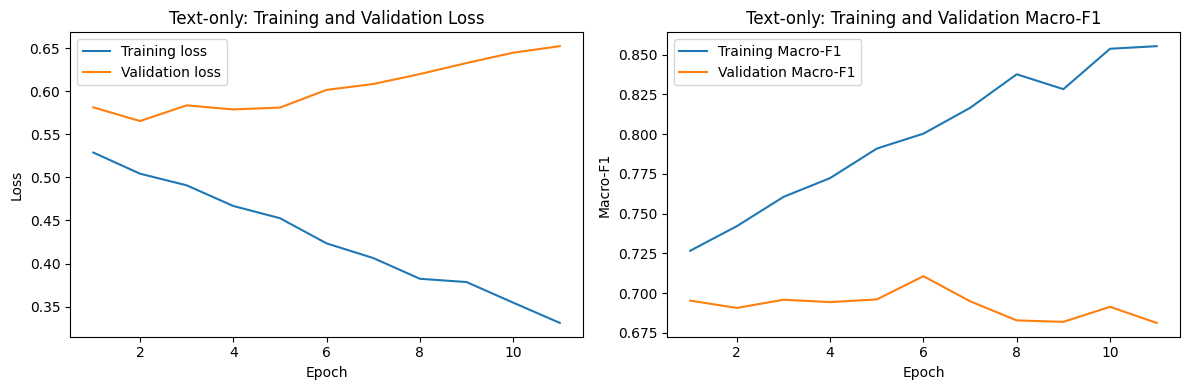


Text-only model training completed.


In [ ]:
# CLASSIFICATION MODEL
class FeatureClassifier(torch.nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim=256,
        dropout=0.3,
        num_classes=2
    ):
        super().__init__()
        self.network = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden_dim),
            torch.nn.GELU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(hidden_dim, num_classes)
        )
    def forward(self, x):
        return self.network(x)
# CREATE FEATURE DATALOADERS
CLASSIFIER_BATCH_SIZE = 64
def create_feature_loader(features, labels, shuffle=False):
    dataset_tensor = TensorDataset(features, labels)
    return DataLoader(
        dataset_tensor,
        batch_size=CLASSIFIER_BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0
    )
# MODEL EVALUATION FUNCTION
def evaluate_feature_model(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_labels = []
    all_predictions = []
    all_probabilities = []
    with torch.inference_mode():
        for features, labels in loader:
            features = features.to(DEVICE)
            labels = labels.to(DEVICE)
            outputs = model(features)
            loss = criterion(outputs, labels)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = torch.argmax(outputs, dim=1)
            total_loss += loss.item() * len(labels)
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)
    all_probabilities = np.array(all_probabilities)
    return {
        "loss": total_loss / len(all_labels),
        "accuracy": accuracy_score(
            all_labels, all_predictions
        ),
        "precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "auroc": roc_auc_score(
            all_labels, all_probabilities[:, 1]
        )
    }
# REUSABLE CLASSIFIER TRAINING FUNCTION
def train_feature_classifier(
    train_features,
    train_labels,
    validation_features,
    validation_labels,
    input_dim,
    model_name,
    learning_rate=0.001,
    weight_decay=0.0001,
    hidden_dim=256,
    dropout=0.3,
    max_epochs=30,
    patience=5
):
    # Create loaders
    train_loader = create_feature_loader(
        train_features, train_labels, shuffle=True
    )
    train_eval_loader = create_feature_loader(
        train_features, train_labels, shuffle=False
    )
    validation_loader = create_feature_loader(
        validation_features, validation_labels, shuffle=False
    )
    # Calculate class weights using training labels only
    class_counts = torch.bincount(
        train_labels,
        minlength=2
    ).float()
    class_weights = (
        len(train_labels) / (2 * class_counts)
    ).to(DEVICE)
    # Initialise model
    model = FeatureClassifier(
        input_dim=input_dim,
        hidden_dim=hidden_dim,
        dropout=dropout
    ).to(DEVICE)
    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights
    )
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )
    best_val_f1 = -float("inf")
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    history = []
    # Training loop
    for epoch in range(1, max_epochs + 1):
        model.train()
        for features, labels in train_loader:
            features = features.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(features)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )
            optimizer.step()
        # Evaluate training and validation performance
        train_metrics = evaluate_feature_model(
            model, train_eval_loader, criterion
        )
        val_metrics = evaluate_feature_model(
            model, validation_loader, criterion
        )
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_macro_f1": train_metrics["macro_f1"],
            "validation_loss": val_metrics["loss"],
            "validation_macro_f1": val_metrics["macro_f1"]
        })
        print(
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train F1: {train_metrics['macro_f1']:.4f} | "
            f"Validation F1: {val_metrics['macro_f1']:.4f}"
        )
        # Select checkpoint using validation Macro-F1.
        # Break ties using validation loss.
        improved = (
            val_metrics["macro_f1"] > best_val_f1
            or (
                val_metrics["macro_f1"] == best_val_f1
                and val_metrics["loss"] < best_val_loss
            )
        )
        if improved:
            best_val_f1 = val_metrics["macro_f1"]
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(
                f"\nEarly stopping at epoch {epoch}."
            )
            break
    # Restore best model
    model.load_state_dict(best_state)
    # Save best checkpoint
    checkpoint_path = (
        CHECKPOINT_DIR / f"{model_name}_best.pt"
    )
    torch.save({
        "model_state_dict": model.state_dict(),
        "input_dim": input_dim,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_val_f1,
        "class_weights": class_weights.cpu()
    }, checkpoint_path)
    # Final validation metrics from restored best model
    final_validation_metrics = evaluate_feature_model(
        model, validation_loader, criterion
    )
    print("\nBEST MODEL")
    print("Best epoch:", best_epoch)
    print("Best validation Macro-F1:", round(best_val_f1, 4))
    print("Checkpoint:", checkpoint_path)
    return (
        model,
        pd.DataFrame(history),
        final_validation_metrics
    )
# TRAIN MODEL 1 - TEXT ONLY
text_train_features = scaled_features["train"]["text_features"]
text_val_features = scaled_features["validation"]["text_features"]
train_labels = scaled_features["train"]["labels"]
validation_labels = scaled_features["validation"]["labels"]
text_model, text_history, text_validation_metrics = (
    train_feature_classifier(
        train_features=text_train_features,
        train_labels=train_labels,
        validation_features=text_val_features,
        validation_labels=validation_labels,
        input_dim=768,
        model_name="text_only"
    )
)
# Display validation performance
print("\nTEXT-ONLY VALIDATION PERFORMANCE")
display(
    pd.DataFrame([text_validation_metrics]).round(4)
)
# Plot learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(
    text_history["epoch"],
    text_history["train_loss"],
    label="Training loss"
)
axes[0].plot(
    text_history["epoch"],
    text_history["validation_loss"],
    label="Validation loss"
)
axes[0].set_title("Text-only: Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(
    text_history["epoch"],
    text_history["train_macro_f1"],
    label="Training Macro-F1"
)
axes[1].plot(
    text_history["epoch"],
    text_history["validation_macro_f1"],
    label="Validation Macro-F1"
)
axes[1].set_title("Text-only: Training and Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
plt.tight_layout()
plt.show()
print("\nText-only model training completed.")

Model 2 — Image-only Classification (EfficientNet-B0)

Epoch 01/30 | Train F1: 0.7599 | Validation F1: 0.7154
Epoch 02/30 | Train F1: 0.7952 | Validation F1: 0.7195
Epoch 03/30 | Train F1: 0.8225 | Validation F1: 0.7118
Epoch 04/30 | Train F1: 0.8585 | Validation F1: 0.6896
Epoch 05/30 | Train F1: 0.8855 | Validation F1: 0.7048
Epoch 06/30 | Train F1: 0.9109 | Validation F1: 0.7026
Epoch 07/30 | Train F1: 0.9235 | Validation F1: 0.7082

Early stopping at epoch 7.

BEST MODEL
Best epoch: 2
Best validation Macro-F1: 0.7195
Checkpoint: /content/CrisisMMD_Project/checkpoints/image_only_best.pt

IMAGE-ONLY VALIDATION PERFORMANCE


,loss,accuracy,precision,recall,macro_f1,auroc
0,0.5502,0.73,0.717,0.7285,0.7195,0.7966


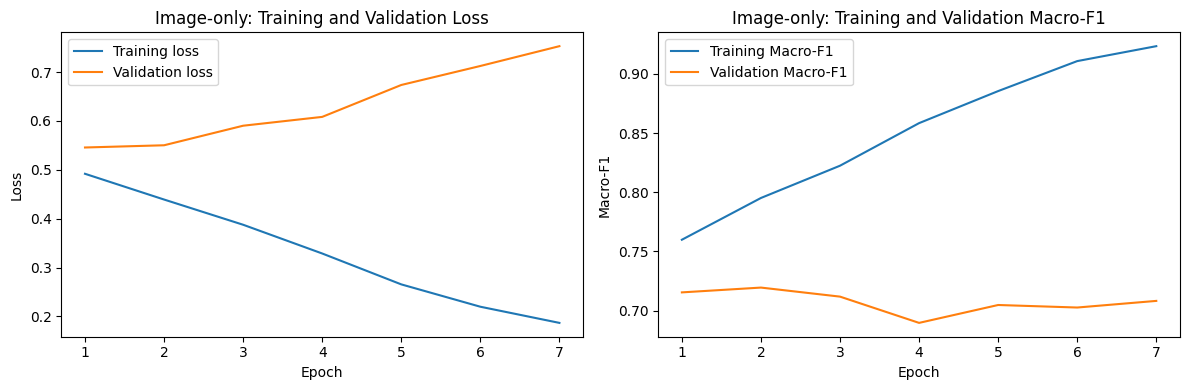


Image-only model training completed.


In [ ]:
# Training and validation features
image_train_features = (
    scaled_features["train"]["image_features"]
)
image_val_features = (
    scaled_features["validation"]["image_features"]
)
# Training and validation labels
train_labels = scaled_features["train"]["labels"]
validation_labels = scaled_features["validation"]["labels"]
# TRAIN IMAGE-ONLY CLASSIFIER
image_model, image_history, image_validation_metrics = (
    train_feature_classifier(
        train_features=image_train_features,
        train_labels=train_labels,
        validation_features=image_val_features,
        validation_labels=validation_labels,
        input_dim=1280,
        model_name="image_only"
    )
)
# DISPLAY VALIDATION PERFORMANCE
print("\nIMAGE-ONLY VALIDATION PERFORMANCE")
display(
    pd.DataFrame([image_validation_metrics]).round(4)
)
# PLOT LEARNING CURVES
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Training and validation loss
axes[0].plot(
    image_history["epoch"],
    image_history["train_loss"],
    label="Training loss"
)
axes[0].plot(
    image_history["epoch"],
    image_history["validation_loss"],
    label="Validation loss"
)
axes[0].set_title(
    "Image-only: Training and Validation Loss"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
# Training and validation Macro-F1
axes[1].plot(
    image_history["epoch"],
    image_history["train_macro_f1"],
    label="Training Macro-F1"
)
axes[1].plot(
    image_history["epoch"],
    image_history["validation_macro_f1"],
    label="Validation Macro-F1"
)
axes[1].set_title(
    "Image-only: Training and Validation Macro-F1"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
plt.tight_layout()
plt.show()
print("\nImage-only model training completed.")

Model 3 — Early Fusion (DistilBERT + EfficientNet-B0)

EARLY FUSION FEATURE SHAPES
Training: torch.Size([13608, 2048])
Validation: torch.Size([2237, 2048])
Epoch 01/30 | Train F1: 0.8069 | Validation F1: 0.7599
Epoch 02/30 | Train F1: 0.8375 | Validation F1: 0.7536
Epoch 03/30 | Train F1: 0.8822 | Validation F1: 0.7490
Epoch 04/30 | Train F1: 0.9047 | Validation F1: 0.7375
Epoch 05/30 | Train F1: 0.9243 | Validation F1: 0.7360
Epoch 06/30 | Train F1: 0.9415 | Validation F1: 0.7339

Early stopping at epoch 6.

BEST MODEL
Best epoch: 1
Best validation Macro-F1: 0.7599
Checkpoint: /content/CrisisMMD_Project/checkpoints/early_fusion_best.pt

EARLY FUSION VALIDATION PERFORMANCE


,loss,accuracy,precision,recall,macro_f1,auroc
0,0.4797,0.7711,0.7565,0.7664,0.7599,0.8508


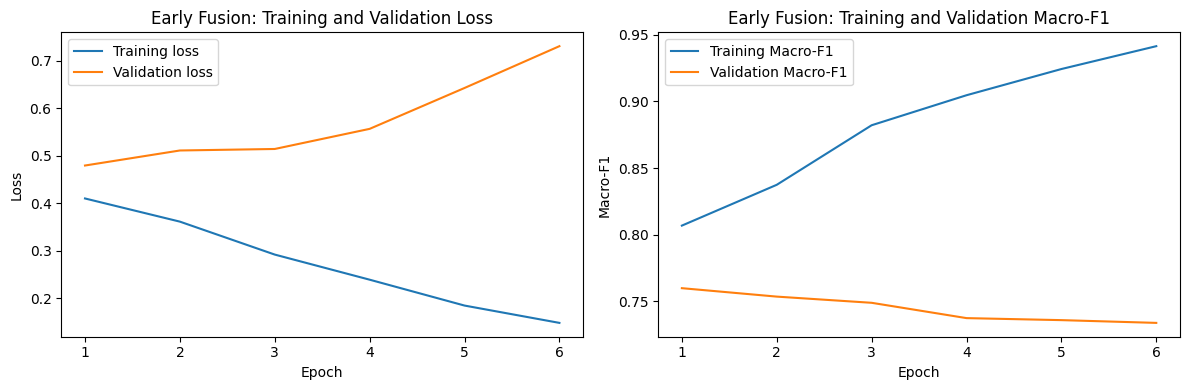


Early fusion model training completed.


In [ ]:
# Concatenate standardised text and image features
early_train_features = torch.cat(
    [
        scaled_features["train"]["text_features"],
        scaled_features["train"]["image_features"]
    ],
    dim=1
)
early_val_features = torch.cat(
    [
        scaled_features["validation"]["text_features"],
        scaled_features["validation"]["image_features"]
    ],
    dim=1
)
# Use the shared labels
train_labels = scaled_features["train"]["labels"]
validation_labels = scaled_features["validation"]["labels"]
# VERIFY FEATURE ALIGNMENT
assert early_train_features.shape == (13608, 2048)
assert early_val_features.shape == (2237, 2048)
print("EARLY FUSION FEATURE SHAPES")
print("Training:", early_train_features.shape)
print("Validation:", early_val_features.shape)
# TRAIN EARLY FUSION CLASSIFIER
early_fusion_model, early_fusion_history, early_fusion_validation_metrics = (
    train_feature_classifier(
        train_features=early_train_features,
        train_labels=train_labels,
        validation_features=early_val_features,
        validation_labels=validation_labels,
        input_dim=2048,
        model_name="early_fusion"
    )
)
# DISPLAY VALIDATION PERFORMANCE
print("\nEARLY FUSION VALIDATION PERFORMANCE")
display(
    pd.DataFrame(
        [early_fusion_validation_metrics]
    ).round(4)
)
# PLOT LEARNING CURVES
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(
    early_fusion_history["epoch"],
    early_fusion_history["train_loss"],
    label="Training loss"
)
axes[0].plot(
    early_fusion_history["epoch"],
    early_fusion_history["validation_loss"],
    label="Validation loss"
)
axes[0].set_title(
    "Early Fusion: Training and Validation Loss"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(
    early_fusion_history["epoch"],
    early_fusion_history["train_macro_f1"],
    label="Training Macro-F1"
)
axes[1].plot(
    early_fusion_history["epoch"],
    early_fusion_history["validation_macro_f1"],
    label="Validation Macro-F1"
)
axes[1].set_title(
    "Early Fusion: Training and Validation Macro-F1"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
plt.tight_layout()
plt.show()
print("\nEarly fusion model training completed.")

Model 4 — Late Fusion (Prediction-Level Combination)

In [ ]:
# GENERATE CLASS PROBABILITIES
def get_model_probabilities(model, features):
    loader = create_feature_loader(
        features,
        validation_labels,
        shuffle=False
    )
    model.eval()
    probabilities = []
    with torch.inference_mode():
        for batch_features, _ in loader:
            batch_features = batch_features.to(DEVICE)
            outputs = model(batch_features)
            batch_probabilities = torch.softmax(
                outputs, dim=1
            )
            probabilities.append(
                batch_probabilities.cpu().numpy()
            )
    return np.concatenate(probabilities, axis=0)
# Validation predictions from both models
text_val_probabilities = get_model_probabilities(
    text_model,
    scaled_features["validation"]["text_features"]
)
image_val_probabilities = get_model_probabilities(
    image_model,
    scaled_features["validation"]["image_features"]
)
y_val = validation_labels.numpy()
# Check prediction alignment
assert len(text_val_probabilities) == len(y_val)
assert len(image_val_probabilities) == len(y_val)
print("TEXT PROBABILITIES:", text_val_probabilities.shape)
print("IMAGE PROBABILITIES:", image_val_probabilities.shape)
# EVALUATION FUNCTION
def calculate_metrics(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    return {
        "accuracy": accuracy_score(
            y_true, predictions
        ),
        "precision": precision_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),
        "auroc": roc_auc_score(
            y_true, probabilities[:, 1]
        )
    }
# SEARCH FOR THE BEST FUSION WEIGHT
# Alpha represents the weight assigned to text.
# (1 - alpha) represents the weight assigned to images.
late_fusion_results = []
for alpha in np.round(
    np.arange(0, 1.01, 0.05), 2
):
    fused_probabilities = (
        alpha * text_val_probabilities
        + (1 - alpha) * image_val_probabilities
    )
    metrics = calculate_metrics(
        y_val,
        fused_probabilities
    )
    late_fusion_results.append({
        "Text weight": alpha,
        "Image weight": round(1 - alpha, 2),
        **metrics
    })
# SELECT BEST WEIGHT USING VALIDATION MACRO-F1
late_fusion_df = pd.DataFrame(
    late_fusion_results
)
# If there is a tie in Macro-F1, prefer the
# highest accuracy. Do not use test data.
best_result = late_fusion_df.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
).iloc[0]
BEST_TEXT_WEIGHT = float(best_result["Text weight"])
BEST_IMAGE_WEIGHT = float(best_result["Image weight"])
late_fusion_validation_metrics = {
    metric: float(best_result[metric])
    for metric in [
        "accuracy",
        "precision",
        "recall",
        "macro_f1",
        "auroc"
    ]
}
print("\nLATE FUSION WEIGHT COMPARISON")
display(late_fusion_df.round(4))
print("\nSELECTED LATE FUSION WEIGHTS")
print("Text weight:", BEST_TEXT_WEIGHT)
print("Image weight:", BEST_IMAGE_WEIGHT)
print("\nBEST LATE FUSION VALIDATION PERFORMANCE")
display(
    pd.DataFrame([
        late_fusion_validation_metrics
    ]).round(4)
)
# SAVE SELECTED FUSION CONFIGURATION
late_fusion_configuration = {
    "text_weight": BEST_TEXT_WEIGHT,
    "image_weight": BEST_IMAGE_WEIGHT,
    "selection_metric": "validation Macro-F1",
    "validation_metrics": late_fusion_validation_metrics
}
print("\nLate fusion configuration saved successfully.")

TEXT PROBABILITIES: (2237, 2)
IMAGE PROBABILITIES: (2237, 2)

LATE FUSION WEIGHT COMPARISON


,Text weight,Image weight,accuracy,precision,recall,macro_f1,auroc
0,0.00,1.00,0.7300,0.7170,0.7285,0.7195,0.7966
1,0.05,0.95,0.7349,0.7218,0.7334,0.7244,0.8053
2,0.10,0.90,0.7398,0.7266,0.7383,0.7294,0.8134
3,0.15,0.85,0.7447,0.7313,0.7430,0.7343,0.8210
4,0.20,0.80,0.7506,0.7369,0.7486,0.7401,0.8275
5,0.25,0.75,0.7550,0.7412,0.7526,0.7445,0.8331
6,0.30,0.70,0.7564,0.7421,0.7530,0.7454,0.8375
7,0.35,0.65,0.7658,0.7512,0.7614,0.7546,0.8406
8,0.40,0.60,0.7693,0.7538,0.7615,0.7568,0.8421
9,0.45,0.55,0.7747,0.7589,0.7643,0.7612,0.8422



SELECTED LATE FUSION WEIGHTS
Text weight: 0.45
Image weight: 0.55

BEST LATE FUSION VALIDATION PERFORMANCE


,accuracy,precision,recall,macro_f1,auroc
0,0.7747,0.7589,0.7643,0.7612,0.8422



Late fusion configuration saved successfully.


## Validation Model Comparison

In [ ]:
# Validation performance comparison
validation_comparison = pd.DataFrame([
    {
        "Model": "Text-only",
        **text_validation_metrics
    },
    {
        "Model": "Image-only",
        **image_validation_metrics
    },
    {
        "Model": "Early fusion",
        **early_fusion_validation_metrics
    },
    {
        "Model": "Late fusion",
        **late_fusion_validation_metrics
    }
])
validation_comparison = validation_comparison[
    [
        "Model",
        "accuracy",
        "precision",
        "recall",
        "macro_f1",
        "auroc"
    ]
].sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)
print("VALIDATION PERFORMANCE COMPARISON")
display(
    validation_comparison
    .drop(columns=["loss"], errors="ignore")
    .round(4)
)
# Compare fusion methods against the best unimodal model
best_unimodal_f1 = max(
    text_validation_metrics["macro_f1"],
    image_validation_metrics["macro_f1"]
)
print("\nFUSION IMPROVEMENT ANALYSIS")
print(
    "Early fusion improvement over best unimodal model:",
    round(
        early_fusion_validation_metrics["macro_f1"]
        - best_unimodal_f1,
        4
    )
)
print(
    "Late fusion improvement over best unimodal model:",
    round(
        late_fusion_validation_metrics["macro_f1"]
        - best_unimodal_f1,
        4
    )
)
print(
    "Late fusion improvement over early fusion:",
    round(
        late_fusion_validation_metrics["macro_f1"]
        - early_fusion_validation_metrics["macro_f1"],
        4
    )
)

VALIDATION PERFORMANCE COMPARISON


,Model,accuracy,precision,recall,macro_f1,auroc
0,Late fusion,0.7747,0.7589,0.7643,0.7612,0.8422
1,Early fusion,0.7711,0.7565,0.7664,0.7599,0.8508
2,Image-only,0.7300,0.7170,0.7285,0.7195,0.7966
3,Text-only,0.7246,0.7081,0.7156,0.7107,0.7716



FUSION IMPROVEMENT ANALYSIS
Early fusion improvement over best unimodal model: 0.0404
Late fusion improvement over best unimodal model: 0.0418
Late fusion improvement over early fusion: 0.0013


## Overfitting Assessment

In [ ]:
# Compare training and validation performance
# at each model's best validation Macro-F1 epoch.
histories = {
    "Text-only": text_history,
    "Image-only": image_history,
    "Early fusion": early_fusion_history
}
overfitting_results = []
for model_name, history in histories.items():
    best_index = history["validation_macro_f1"].idxmax()
    best_row = history.loc[best_index]
    f1_gap = (
        best_row["train_macro_f1"]
        - best_row["validation_macro_f1"]
    )
    loss_gap = (
        best_row["validation_loss"]
        - best_row["train_loss"]
    )
    overfitting_results.append({
        "Model": model_name,
        "Best epoch": int(best_row["epoch"]),
        "Training Macro-F1": best_row["train_macro_f1"],
        "Validation Macro-F1": best_row["validation_macro_f1"],
        "Macro-F1 gap": f1_gap,
        "Training loss": best_row["train_loss"],
        "Validation loss": best_row["validation_loss"],
        "Loss gap": loss_gap
    })
overfitting_df = pd.DataFrame(overfitting_results)
print("OVERFITTING ASSESSMENT")
display(overfitting_df.round(4))

OVERFITTING ASSESSMENT


,Model,Best epoch,Training Macro-F1,Validation Macro-F1,Macro-F1 gap,Training loss,Validation loss,Loss gap
0,Text-only,6,0.8003,0.7107,0.0896,0.4234,0.6016,0.1782
1,Image-only,2,0.7952,0.7195,0.0757,0.4392,0.5502,0.1110
2,Early fusion,1,0.8069,0.7599,0.0469,0.4103,0.4797,0.0694


## Regularisation Experiments

In [ ]:
# Regularisation configuration
REGULARISATION_SETTINGS = {
    "hidden_dim": 128,
    "dropout": 0.5,
    "learning_rate": 0.0003,
    "weight_decay": 0.01,
    "max_epochs": 30,
    "patience": 5
}
# REGULARISED TEXT-ONLY MODEL
text_model_reg, text_history_reg, text_validation_metrics_reg = (
    train_feature_classifier(
        train_features=scaled_features["train"]["text_features"],
        train_labels=train_labels,
        validation_features=scaled_features["validation"]["text_features"],
        validation_labels=validation_labels,
        input_dim=768,
        model_name="text_only_regularised",
        **REGULARISATION_SETTINGS
    )
)
# REGULARISED IMAGE-ONLY MODEL
image_model_reg, image_history_reg, image_validation_metrics_reg = (
    train_feature_classifier(
        train_features=scaled_features["train"]["image_features"],
        train_labels=train_labels,
        validation_features=scaled_features["validation"]["image_features"],
        validation_labels=validation_labels,
        input_dim=1280,
        model_name="image_only_regularised",
        **REGULARISATION_SETTINGS
    )
)
# REGULARISED EARLY-FUSION MODEL
early_fusion_model_reg, early_fusion_history_reg, early_fusion_validation_metrics_reg = (
    train_feature_classifier(
        train_features=early_train_features,
        train_labels=train_labels,
        validation_features=early_val_features,
        validation_labels=validation_labels,
        input_dim=2048,
        model_name="early_fusion_regularised",
        **REGULARISATION_SETTINGS
    )
)
print("\nREGULARISED MODEL TRAINING COMPLETED.")

Epoch 01/30 | Train F1: 0.7210 | Validation F1: 0.6990
Epoch 02/30 | Train F1: 0.7283 | Validation F1: 0.6997
Epoch 03/30 | Train F1: 0.7480 | Validation F1: 0.7123
Epoch 04/30 | Train F1: 0.7509 | Validation F1: 0.7092
Epoch 05/30 | Train F1: 0.7587 | Validation F1: 0.7174
Epoch 06/30 | Train F1: 0.7656 | Validation F1: 0.7061
Epoch 07/30 | Train F1: 0.7753 | Validation F1: 0.7103
Epoch 08/30 | Train F1: 0.7834 | Validation F1: 0.7143
Epoch 09/30 | Train F1: 0.7888 | Validation F1: 0.7072
Epoch 10/30 | Train F1: 0.7908 | Validation F1: 0.7030

Early stopping at epoch 10.

BEST MODEL
Best epoch: 5
Best validation Macro-F1: 0.7174
Checkpoint: /content/CrisisMMD_Project/checkpoints/text_only_regularised_best.pt
Epoch 01/30 | Train F1: 0.7506 | Validation F1: 0.7139
Epoch 02/30 | Train F1: 0.7722 | Validation F1: 0.7160
Epoch 03/30 | Train F1: 0.7920 | Validation F1: 0.7236
Epoch 04/30 | Train F1: 0.8018 | Validation F1: 0.7221
Epoch 05/30 | Train F1: 0.8222 | Validation F1: 0.7231
Epoch 

In [ ]:
# BASELINE VS REGULARISED COMPARISON
regularisation_comparison = pd.DataFrame([
    {
        "Model": "Text-only",
        "Version": "Baseline",
        **text_validation_metrics
    },
    {
        "Model": "Text-only",
        "Version": "Regularised",
        **text_validation_metrics_reg
    },
    {
        "Model": "Image-only",
        "Version": "Baseline",
        **image_validation_metrics
    },
    {
        "Model": "Image-only",
        "Version": "Regularised",
        **image_validation_metrics_reg
    },
    {
        "Model": "Early fusion",
        "Version": "Baseline",
        **early_fusion_validation_metrics
    },
    {
        "Model": "Early fusion",
        "Version": "Regularised",
        **early_fusion_validation_metrics_reg
    }
])
print("BASELINE VS REGULARISED PERFORMANCE")
display(
    regularisation_comparison.round(4)
)

BASELINE VS REGULARISED PERFORMANCE


,Model,Version,loss,accuracy,precision,recall,macro_f1,auroc
0,Text-only,Baseline,0.6016,0.7246,0.7081,0.7156,0.7107,0.7716
1,Text-only,Regularised,0.5681,0.7318,0.7149,0.7216,0.7174,0.7792
2,Image-only,Baseline,0.5502,0.7300,0.7170,0.7285,0.7195,0.7966
3,Image-only,Regularised,0.5462,0.7349,0.7208,0.7315,0.7236,0.7999
4,Early fusion,Baseline,0.4797,0.7711,0.7565,0.7664,0.7599,0.8508
5,Early fusion,Regularised,0.4770,0.7747,0.7596,0.7683,0.7629,0.8535


In [ ]:
# Compare generalisation gaps at each model's
# best validation Macro-F1 epoch.
regularised_histories = {
    "Text-only": text_history_reg,
    "Image-only": image_history_reg,
    "Early fusion": early_fusion_history_reg
}
baseline_histories = {
    "Text-only": text_history,
    "Image-only": image_history,
    "Early fusion": early_fusion_history
}
gap_comparison = []
for model_name in baseline_histories:
    for version, history in [
        ("Baseline", baseline_histories[model_name]),
        ("Regularised", regularised_histories[model_name])
    ]:
        best_row = history.loc[
            history["validation_macro_f1"].idxmax()
        ]
        gap_comparison.append({
            "Model": model_name,
            "Version": version,
            "Best epoch": int(best_row["epoch"]),
            "Training Macro-F1": best_row["train_macro_f1"],
            "Validation Macro-F1": best_row["validation_macro_f1"],
            "Generalisation gap": (
                best_row["train_macro_f1"]
                - best_row["validation_macro_f1"]
            ),
            "Training loss": best_row["train_loss"],
            "Validation loss": best_row["validation_loss"]
        })
gap_comparison_df = pd.DataFrame(gap_comparison)
print("BASELINE VS REGULARISED OVERFITTING COMPARISON")
display(gap_comparison_df.round(4))

BASELINE VS REGULARISED OVERFITTING COMPARISON


,Model,Version,Best epoch,Training Macro-F1,Validation Macro-F1,Generalisation gap,Training loss,Validation loss
0,Text-only,Baseline,6,0.8003,0.7107,0.0896,0.4234,0.6016
1,Text-only,Regularised,5,0.7587,0.7174,0.0413,0.4840,0.5681
2,Image-only,Baseline,2,0.7952,0.7195,0.0757,0.4392,0.5502
3,Image-only,Regularised,3,0.7920,0.7236,0.0683,0.4444,0.5462
4,Early fusion,Baseline,1,0.8069,0.7599,0.0469,0.4103,0.4797
5,Early fusion,Regularised,2,0.8209,0.7629,0.0580,0.3848,0.4770


## Late Fusion Recalibration

In [ ]:
# GENERATE VALIDATION PROBABILITIES
def get_probabilities(model, features):
    loader = DataLoader(
        TensorDataset(features),
        batch_size=CLASSIFIER_BATCH_SIZE,
        shuffle=False
    )
    model.eval()
    probabilities = []
    with torch.inference_mode():
        for (batch_features,) in loader:
            batch_features = batch_features.to(DEVICE)
            outputs = model(batch_features)
            probs = torch.softmax(outputs, dim=1)
            probabilities.append(probs.cpu().numpy())
    return np.concatenate(probabilities, axis=0)
y_val = scaled_features["validation"]["labels"].numpy()
# Baseline predictions
baseline_text_probs = get_probabilities(
    text_model,
    scaled_features["validation"]["text_features"]
)
baseline_image_probs = get_probabilities(
    image_model,
    scaled_features["validation"]["image_features"]
)
# Regularised predictions
regularised_text_probs = get_probabilities(
    text_model_reg,
    scaled_features["validation"]["text_features"]
)
regularised_image_probs = get_probabilities(
    image_model_reg,
    scaled_features["validation"]["image_features"]
)
# SEARCH FOR OPTIMAL FUSION WEIGHTS
def tune_late_fusion(text_probs, image_probs, y_true):
    results = []
    for alpha in np.round(np.arange(0, 1.01, 0.05), 2):
        probabilities = (
            alpha * text_probs
            + (1 - alpha) * image_probs
        )
        metrics = calculate_metrics(
            y_true,
            probabilities
        )
        results.append({
            "Text weight": alpha,
            "Image weight": round(1 - alpha, 2),
            **metrics
        })
    results_df = pd.DataFrame(results)
    best = results_df.sort_values(
        ["macro_f1", "accuracy"],
        ascending=False
    ).iloc[0]
    return results_df, best
# Tune baseline late fusion
baseline_late_df, baseline_late_best = tune_late_fusion(
    baseline_text_probs,
    baseline_image_probs,
    y_val
)
# Tune regularised late fusion
regularised_late_df, regularised_late_best = tune_late_fusion(
    regularised_text_probs,
    regularised_image_probs,
    y_val
)
# COMPARE BASELINE AND REGULARISED LATE FUSION
late_fusion_selection = pd.DataFrame([
    {
        "Version": "Baseline",
        "Text weight": baseline_late_best["Text weight"],
        "Image weight": baseline_late_best["Image weight"],
        "accuracy": baseline_late_best["accuracy"],
        "precision": baseline_late_best["precision"],
        "recall": baseline_late_best["recall"],
        "macro_f1": baseline_late_best["macro_f1"],
        "auroc": baseline_late_best["auroc"]
    },
    {
        "Version": "Regularised",
        "Text weight": regularised_late_best["Text weight"],
        "Image weight": regularised_late_best["Image weight"],
        "accuracy": regularised_late_best["accuracy"],
        "precision": regularised_late_best["precision"],
        "recall": regularised_late_best["recall"],
        "macro_f1": regularised_late_best["macro_f1"],
        "auroc": regularised_late_best["auroc"]
    }
])
print("LATE FUSION MODEL SELECTION")
display(late_fusion_selection.round(4))
# SELECT BEST LATE FUSION CONFIGURATION
if (
    regularised_late_best["macro_f1"]
    > baseline_late_best["macro_f1"]
):
    SELECTED_LATE_FUSION = "Regularised"
    BEST_LATE_RESULT = regularised_late_best
else:
    SELECTED_LATE_FUSION = "Baseline"
    BEST_LATE_RESULT = baseline_late_best
BEST_TEXT_WEIGHT = float(BEST_LATE_RESULT["Text weight"])
BEST_IMAGE_WEIGHT = float(BEST_LATE_RESULT["Image weight"])
late_fusion_validation_metrics = {
    metric: float(BEST_LATE_RESULT[metric])
    for metric in [
        "accuracy", "precision", "recall", "macro_f1", "auroc"
    ]
}
print("\nSELECTED LATE FUSION VERSION:", SELECTED_LATE_FUSION)
print("Text weight:", BEST_TEXT_WEIGHT)
print("Image weight:", BEST_IMAGE_WEIGHT)
print("\nSELECTED LATE FUSION VALIDATION METRICS")
display(pd.DataFrame([
    late_fusion_validation_metrics
]).round(4))

LATE FUSION MODEL SELECTION


,Version,Text weight,Image weight,accuracy,precision,recall,macro_f1,auroc
0,Baseline,0.45,0.55,0.7747,0.7589,0.7643,0.7612,0.8422
1,Regularised,0.55,0.45,0.7635,0.7472,0.7527,0.7496,0.8438



SELECTED LATE FUSION VERSION: Baseline
Text weight: 0.45
Image weight: 0.55

SELECTED LATE FUSION VALIDATION METRICS


,accuracy,precision,recall,macro_f1,auroc
0,0.7747,0.7589,0.7643,0.7612,0.8422


In [ ]:
# FINAL MODEL SELECTION
selected_model_versions = {
    "Text-only": "Regularised",
    "Image-only": "Regularised",
    "Early fusion": "Regularised",
    "Late fusion": "Baseline"
}
selected_validation_results = pd.DataFrame([
    {
        "Model": "Text-only",
        "Selected version": "Regularised",
        **text_validation_metrics_reg
    },
    {
        "Model": "Image-only",
        "Selected version": "Regularised",
        **image_validation_metrics_reg
    },
    {
        "Model": "Early fusion",
        "Selected version": "Regularised",
        **early_fusion_validation_metrics_reg
    },
    {
        "Model": "Late fusion",
        "Selected version": "Baseline",
        **late_fusion_validation_metrics
    }
])
print("FINAL MODEL SELECTION")
display(
    selected_validation_results
    .drop(columns=["loss"])
    .round(4)
)
print("\nSelected late-fusion weights:")
print("Text:", BEST_TEXT_WEIGHT)
print("Image:", BEST_IMAGE_WEIGHT)

FINAL MODEL SELECTION


,Model,Selected version,accuracy,precision,recall,macro_f1,auroc
0,Text-only,Regularised,0.7318,0.7149,0.7216,0.7174,0.7792
1,Image-only,Regularised,0.7349,0.7208,0.7315,0.7236,0.7999
2,Early fusion,Regularised,0.7747,0.7596,0.7683,0.7629,0.8535
3,Late fusion,Baseline,0.7747,0.7589,0.7643,0.7612,0.8422



Selected late-fusion weights:
Text: 0.45
Image: 0.55


## Final Test Evaluation

FINAL TEST PERFORMANCE COMPARISON


,Model,accuracy,precision,recall,macro_f1,auroc
0,Text-only,0.7403,0.7262,0.7273,0.7267,0.7972
1,Image-only,0.7389,0.7306,0.7412,0.7322,0.8042
2,Early fusion,0.7631,0.7520,0.7604,0.7547,0.8534
3,Late fusion,0.7689,0.7564,0.7598,0.7579,0.8527



TEXT-ONLY — CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    informative     0.7907    0.7844    0.7876      1373
not_informative     0.6617    0.6701    0.6659       864

       accuracy                         0.7403      2237
      macro avg     0.7262    0.7273    0.7267      2237
   weighted avg     0.7409    0.7403    0.7406      2237


IMAGE-ONLY — CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    informative     0.8236    0.7312    0.7747      1373
not_informative     0.6375    0.7512    0.6897       864

       accuracy                         0.7389      2237
      macro avg     0.7306    0.7412    0.7322      2237
   weighted avg     0.7517    0.7389    0.7419      2237


EARLY FUSION — CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    informative     0.8301    0.7720    0.8000      1373
not_informative     0.6740    0.7488    0.7094       864

       accuracy             

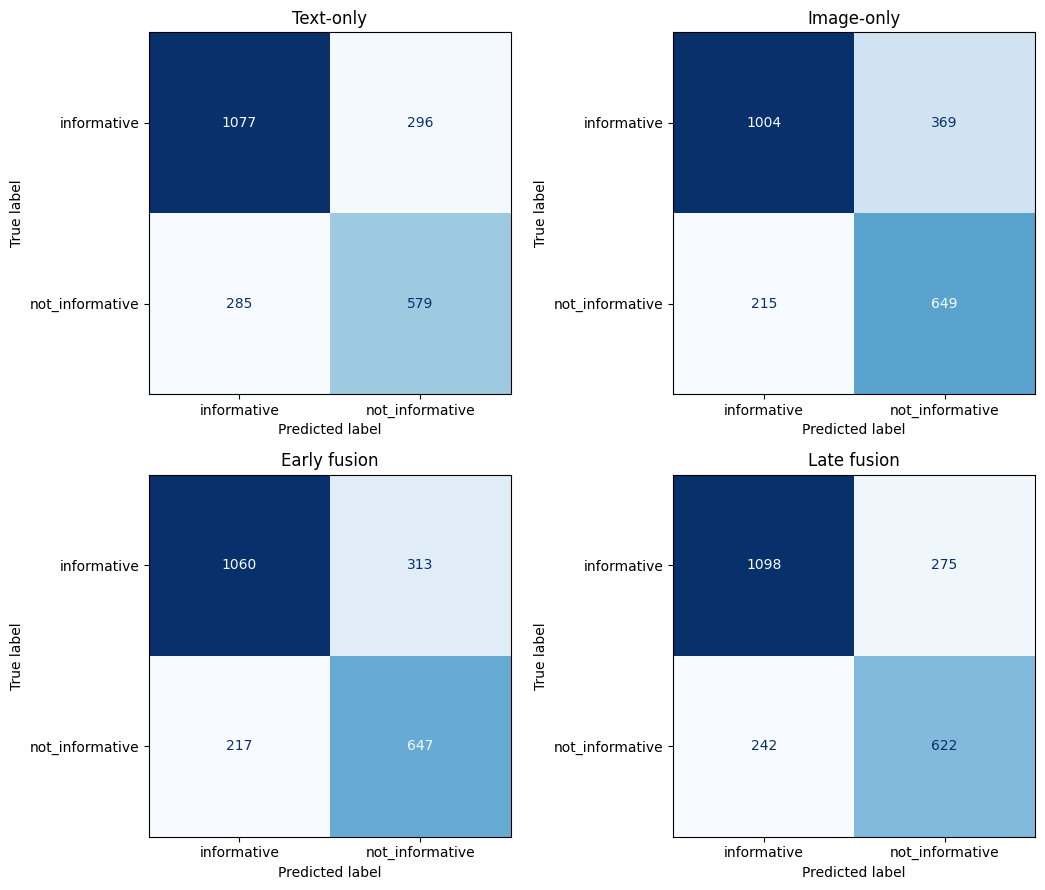

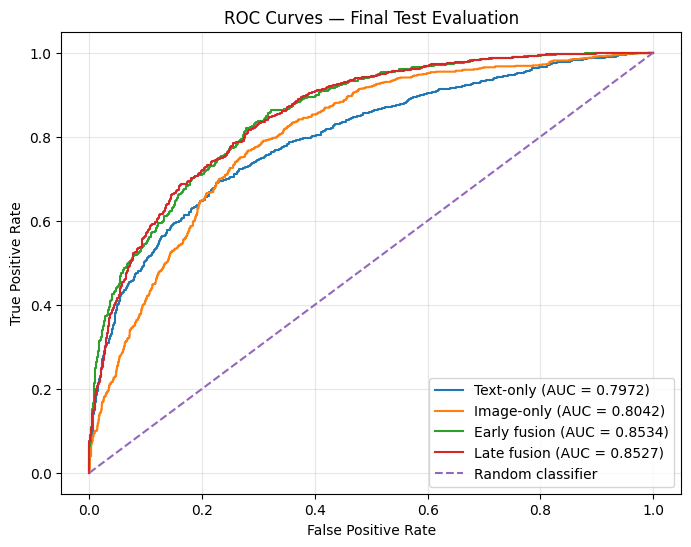


Final test predictions saved successfully.
Test records evaluated: 2237


In [ ]:
# PREPARE TEST DATA
y_test = scaled_features["test"]["labels"].numpy()
test_text_features = scaled_features["test"]["text_features"]
test_image_features = scaled_features["test"]["image_features"]
test_early_features = torch.cat(
    [test_text_features, test_image_features],
    dim=1
)
# GENERATE TEST PROBABILITIES
# Regularised text model
text_test_probs = get_probabilities(
    text_model_reg,
    test_text_features
)
# Regularised image model
image_test_probs = get_probabilities(
    image_model_reg,
    test_image_features
)
# Regularised early-fusion model
early_test_probs = get_probabilities(
    early_fusion_model_reg,
    test_early_features
)
# Baseline late fusion
# Uses the original baseline text and image models.
baseline_text_test_probs = get_probabilities(
    text_model,
    test_text_features
)
baseline_image_test_probs = get_probabilities(
    image_model,
    test_image_features
)
late_test_probs = (
    BEST_TEXT_WEIGHT * baseline_text_test_probs
    + BEST_IMAGE_WEIGHT * baseline_image_test_probs
)
# STORE SELECTED MODEL PREDICTIONS
test_probabilities = {
    "Text-only": text_test_probs,
    "Image-only": image_test_probs,
    "Early fusion": early_test_probs,
    "Late fusion": late_test_probs
}
test_predictions = {
    name: np.argmax(probs, axis=1)
    for name, probs in test_probabilities.items()
}
# CALCULATE TEST METRICS
test_results = []
for model_name, probabilities in test_probabilities.items():
    metrics = calculate_metrics(y_test, probabilities)
    test_results.append({
        "Model": model_name,
        **metrics
    })
final_test_comparison = pd.DataFrame(test_results)
print("FINAL TEST PERFORMANCE COMPARISON")
display(final_test_comparison.round(4))
# CLASSIFICATION REPORTS
for model_name, predictions in test_predictions.items():
    print(f"\n{model_name.upper()} — CLASSIFICATION REPORT")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=[
                ID_TO_LABEL[0],
                ID_TO_LABEL[1]
            ],
            zero_division=0,
            digits=4
        )
    )
# CONFUSION MATRICES
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (model_name, predictions) in zip(
    axes.flatten(),
    test_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            ID_TO_LABEL[0],
            ID_TO_LABEL[1]
        ]
    )
    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )
    ax.set_title(model_name)
plt.tight_layout()
plt.show()
# ROC CURVES
plt.figure(figsize=(8, 6))
for model_name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[:, 1]
    )
    auc_value = roc_auc_score(
        y_test,
        probabilities[:, 1]
    )
    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Final Test Evaluation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
# SAVE TEST PREDICTIONS
np.savez_compressed(
    RESULTS_DIR / "final_test_predictions.npz",
    y_test=y_test,
    text_only_probabilities=text_test_probs,
    image_only_probabilities=image_test_probs,
    early_fusion_probabilities=early_test_probs,
    late_fusion_probabilities=late_test_probs
)
print("\nFinal test predictions saved successfully.")
print("Test records evaluated:", len(y_test))

## Efficiency Assessment

In [ ]:
def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
def benchmark_classifier(model, features, batch_size=256, repeats=5):
    model.eval()
    n_samples = min(len(features), 1024)
    sample = features[:n_samples]
    def run_inference():
        with torch.inference_mode():
            for start in range(0, n_samples, batch_size):
                batch = sample[start:start + batch_size].to(DEVICE)
                model(batch)
        sync_device()
    # Warm-up
    run_inference()
    timings = []
    for _ in range(repeats):
        sync_device()
        start_time = time.perf_counter()
        run_inference()
        elapsed = time.perf_counter() - start_time
        timings.append(elapsed)
    median_time = np.median(timings)
    return {
        "Records benchmarked": n_samples,
        "Trainable parameters": sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        ),
        "Median inference time (seconds)": median_time,
        "Time per record (ms)": (
            median_time / n_samples * 1000
        ),
        "Records per second": n_samples / median_time
    }
# Selected models
efficiency_results = []
selected_models_for_benchmark = [
    (
        "Text-only",
        text_model_reg,
        scaled_features["validation"]["text_features"]
    ),
    (
        "Image-only",
        image_model_reg,
        scaled_features["validation"]["image_features"]
    ),
    (
        "Early fusion",
        early_fusion_model_reg,
        early_val_features
    )
]
for name, model, features in selected_models_for_benchmark:
    efficiency_results.append({
        "Model": name,
        **benchmark_classifier(model, features)
    })
# Late fusion: benchmark both baseline classifiers together.
def benchmark_late_fusion(
    text_features,
    image_features,
    batch_size=256,
    repeats=5
):
    n_samples = min(len(text_features), 1024)
    text_sample = text_features[:n_samples]
    image_sample = image_features[:n_samples]
    text_model.eval()
    image_model.eval()
    def run_inference():
        with torch.inference_mode():
            for start in range(0, n_samples, batch_size):
                end = start + batch_size
                text_batch = text_sample[start:end].to(DEVICE)
                image_batch = image_sample[start:end].to(DEVICE)
                text_probs = torch.softmax(
                    text_model(text_batch), dim=1
                )
                image_probs = torch.softmax(
                    image_model(image_batch), dim=1
                )
                _ = (
                    BEST_TEXT_WEIGHT * text_probs
                    + BEST_IMAGE_WEIGHT * image_probs
                )
        sync_device()
    run_inference()
    timings = []
    for _ in range(repeats):
        sync_device()
        start_time = time.perf_counter()
        run_inference()
        timings.append(time.perf_counter() - start_time)
    median_time = np.median(timings)
    return {
        "Records benchmarked": n_samples,
        "Trainable parameters": (
            sum(p.numel() for p in text_model.parameters())
            + sum(p.numel() for p in image_model.parameters())
        ),
        "Median inference time (seconds)": median_time,
        "Time per record (ms)": median_time / n_samples * 1000,
        "Records per second": n_samples / median_time
    }
efficiency_results.append({
    "Model": "Late fusion",
    **benchmark_late_fusion(
        scaled_features["validation"]["text_features"],
        scaled_features["validation"]["image_features"]
    )
})
efficiency_df = pd.DataFrame(efficiency_results)
print("MODEL EFFICIENCY COMPARISON")
display(efficiency_df.round(4))
print("\nBenchmark device:", DEVICE)

MODEL EFFICIENCY COMPARISON


,Model,Records benchmarked,Trainable parameters,Median inference time (seconds),Time per record (ms),Records per second
0,Text-only,1024,98690,0.0018,0.0017,580231.1179
1,Image-only,1024,164226,0.0021,0.0021,480191.1761
2,Early fusion,1024,262530,0.0029,0.0028,352985.0157
3,Late fusion,1024,525828,0.0039,0.0038,263097.8539



Benchmark device: cuda


## Event-wise Performance Evaluation

EVENT-WISE TEST PERFORMANCE


,Disaster event,Model,Records,Informative support,Not informative support,Accuracy,Precision,Recall,Macro-F1,AUROC
0,california_wildfires,Text-only,240,183,57,0.7958,0.7161,0.6910,0.7013,0.7362
1,california_wildfires,Image-only,240,183,57,0.7708,0.7039,0.7471,0.7166,0.8305
2,california_wildfires,Early fusion,240,183,57,0.8083,0.7364,0.7475,0.7415,0.8449
3,california_wildfires,Late fusion,240,183,57,0.8333,0.7725,0.7518,0.7611,0.8646
4,hurricane_harvey,Text-only,568,388,180,0.7658,0.7312,0.7408,0.7353,0.8089
5,hurricane_harvey,Image-only,568,388,180,0.7535,0.7341,0.7660,0.7376,0.8133
6,hurricane_harvey,Early fusion,568,388,180,0.7623,0.7326,0.7546,0.7392,0.8591
7,hurricane_harvey,Late fusion,568,388,180,0.7729,0.7402,0.7548,0.7459,0.8535
8,hurricane_irma,Text-only,548,348,200,0.6752,0.6540,0.6592,0.6558,0.7147
9,hurricane_irma,Image-only,548,348,200,0.6825,0.6760,0.6894,0.6741,0.7525



EVENT-WISE MACRO-F1 COMPARISON


Model,Early fusion,Image-only,Late fusion,Text-only
Disaster event,,,,
california_wildfires,0.7415,0.7166,0.7611,0.7013
hurricane_harvey,0.7392,0.7376,0.7459,0.7353
hurricane_irma,0.6955,0.6741,0.7050,0.6558
hurricane_maria,0.7600,0.7195,0.7324,0.7214
iraq_iran_earthquake,0.6948,0.7439,0.7591,0.6087
mexico_earthquake,0.7859,0.7945,0.7979,0.7113
srilanka_floods,0.8899,0.8280,0.9238,0.9163


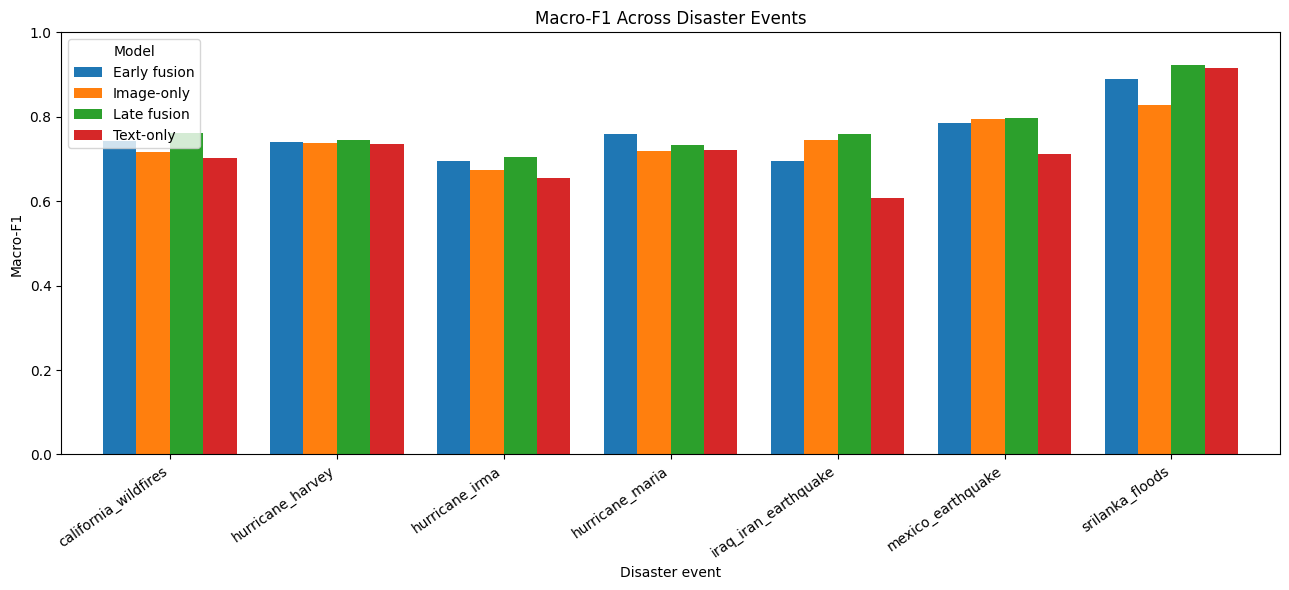


Event-wise evaluation completed.


In [ ]:
# PREPARE TEST METADATA
test_event_df = (
    processed_dataframes["test"]
    .reset_index(drop=True)
    .copy()
)
assert len(test_event_df) == len(y_test)
# Verify label alignment
assert np.array_equal(
    test_event_df["label"].to_numpy(),
    y_test
)
event_performance_results = []
# EVALUATE EACH EVENT AND MODEL
for event_name in sorted(
    test_event_df["event_name"].unique()
):
    event_mask = (
        test_event_df["event_name"].to_numpy()
        == event_name
    )
    event_labels = y_test[event_mask]
    informative_support = np.sum(event_labels == 0)
    not_informative_support = np.sum(event_labels == 1)
    for model_name, probabilities in test_probabilities.items():
        event_probabilities = probabilities[event_mask]
        event_predictions = np.argmax(
            event_probabilities,
            axis=1
        )
        metrics = {
            "Accuracy": accuracy_score(
                event_labels,
                event_predictions
            ),
            "Precision": precision_score(
                event_labels,
                event_predictions,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                event_labels,
                event_predictions,
                average="macro",
                zero_division=0
            ),
            "Macro-F1": f1_score(
                event_labels,
                event_predictions,
                average="macro",
                zero_division=0
            )
        }
        # AUROC requires both classes to be present.
        if len(np.unique(event_labels)) == 2:
            metrics["AUROC"] = roc_auc_score(
                event_labels,
                event_probabilities[:, 1]
            )
        else:
            metrics["AUROC"] = np.nan
        event_performance_results.append({
            "Disaster event": event_name,
            "Model": model_name,
            "Records": len(event_labels),
            "Informative support": informative_support,
            "Not informative support": not_informative_support,
            **metrics
        })
# DISPLAY EVENT-WISE RESULTS
event_performance_df = pd.DataFrame(
    event_performance_results
)
print("EVENT-WISE TEST PERFORMANCE")
display(
    event_performance_df.round(4)
)
# COMPARE MACRO-F1 ACROSS EVENTS
event_f1_table = event_performance_df.pivot(
    index="Disaster event",
    columns="Model",
    values="Macro-F1"
)
print("\nEVENT-WISE MACRO-F1 COMPARISON")
display(
    event_f1_table.round(4)
)
# VISUALISE EVENT-WISE MACRO-F1
ax = event_f1_table.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)
ax.set_title("Macro-F1 Across Disaster Events")
ax.set_xlabel("Disaster event")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()
print("\nEvent-wise evaluation completed.")

## Bootstrap Confidence Interval Analysis

In [ ]:
# BOOTSTRAP CONFIGURATION
N_BOOTSTRAPS = 2000
CONFIDENCE_LEVEL = 0.95
rng = np.random.default_rng(SEED)
classes = np.unique(y_test)
class_indices = {
    label: np.where(y_test == label)[0]
    for label in classes
}
# Confirm both classes are represented
assert len(classes) == 2
# BOOTSTRAP MACRO-F1 FOR ALL MODELS
bootstrap_scores = {
    model_name: []
    for model_name in test_predictions
}
for iteration in tqdm(
    range(N_BOOTSTRAPS),
    desc="Bootstrap resampling"
):
    # Stratified sampling preserves class counts
    sampled_indices = np.concatenate([
        rng.choice(
            class_indices[label],
            size=len(class_indices[label]),
            replace=True
        )
        for label in classes
    ])
    for model_name, predictions in test_predictions.items():
        score = f1_score(
            y_test[sampled_indices],
            predictions[sampled_indices],
            average="macro",
            zero_division=0
        )
        bootstrap_scores[model_name].append(score)
# INDIVIDUAL MODEL CONFIDENCE INTERVALS
bootstrap_results = []
for model_name, scores in bootstrap_scores.items():
    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)
    observed_score = f1_score(
        y_test,
        test_predictions[model_name],
        average="macro"
    )
    bootstrap_results.append({
        "Model": model_name,
        "Test Macro-F1": observed_score,
        "95% CI lower": lower,
        "95% CI upper": upper
    })
bootstrap_df = pd.DataFrame(bootstrap_results)
print("TEST MACRO-F1 BOOTSTRAP CONFIDENCE INTERVALS")
display(bootstrap_df.round(4))
# PAIRED BOOTSTRAP MODEL COMPARISONS
comparisons = [
    ("Early fusion", "Text-only"),
    ("Early fusion", "Image-only"),
    ("Late fusion", "Text-only"),
    ("Late fusion", "Image-only"),
    ("Late fusion", "Early fusion")
]
paired_results = []
for model_a, model_b in comparisons:
    differences = (
        np.array(bootstrap_scores[model_a])
        - np.array(bootstrap_scores[model_b])
    )
    point_difference = (
        f1_score(
            y_test,
            test_predictions[model_a],
            average="macro"
        )
        -
        f1_score(
            y_test,
            test_predictions[model_b],
            average="macro"
        )
    )
    lower = np.percentile(differences, 2.5)
    upper = np.percentile(differences, 97.5)
    paired_results.append({
        "Comparison": f"{model_a} - {model_b}",
        "Macro-F1 difference": point_difference,
        "95% CI lower": lower,
        "95% CI upper": upper,
        "CI includes zero": lower <= 0 <= upper
    })
paired_comparison_df = pd.DataFrame(paired_results)
print("\nPAIRED BOOTSTRAP MODEL COMPARISON")
display(paired_comparison_df.round(4))
# INTERPRETATION
print("\nBOOTSTRAP INTERPRETATION")
for _, row in paired_comparison_df.iterrows():
    if row["CI includes zero"]:
        print(
            row["Comparison"],
            ": Confidence interval includes zero; "
            "the difference is not clearly distinguishable."
        )
    else:
        print(
            row["Comparison"],
            ": Confidence interval excludes zero."
        )
print("\nBootstrap analysis completed.")

Bootstrap resampling:   0%|          | 0/2000 [00:00<?, ?it/s]

TEST MACRO-F1 BOOTSTRAP CONFIDENCE INTERVALS


,Model,Test Macro-F1,95% CI lower,95% CI upper
0,Text-only,0.7267,0.7079,0.7465
1,Image-only,0.7322,0.7136,0.7510
2,Early fusion,0.7547,0.7366,0.7734
3,Late fusion,0.7579,0.7388,0.7762



PAIRED BOOTSTRAP MODEL COMPARISON


,Comparison,Macro-F1 difference,95% CI lower,95% CI upper,CI includes zero
0,Early fusion - Text-only,0.0280,0.0108,0.0459,False
1,Early fusion - Image-only,0.0225,0.0049,0.0399,False
2,Late fusion - Text-only,0.0312,0.0136,0.0501,False
3,Late fusion - Image-only,0.0257,0.0086,0.0434,False
4,Late fusion - Early fusion,0.0032,-0.0111,0.0182,True



BOOTSTRAP INTERPRETATION
Early fusion - Text-only : Confidence interval excludes zero.
Early fusion - Image-only : Confidence interval excludes zero.
Late fusion - Text-only : Confidence interval excludes zero.
Late fusion - Image-only : Confidence interval excludes zero.
Late fusion - Early fusion : Confidence interval includes zero; the difference is not clearly distinguishable.

Bootstrap analysis completed.


## Error Analysis

CLASSIFICATION ERROR SUMMARY


,Model,Correct predictions,Incorrect predictions,Error rate (%),Informative predicted as not informative,Not informative predicted as informative
0,Text-only,1656,581,25.97,296,285
1,Image-only,1653,584,26.11,369,215
2,Early fusion,1707,530,23.69,313,217
3,Late fusion,1720,517,23.11,275,242



ERROR OVERLAP ACROSS MODELS


,Number of models incorrect,Test records
0,0,1255
1,1,368
2,2,198
3,3,216
4,4,200



Records misclassified by all four models: 200


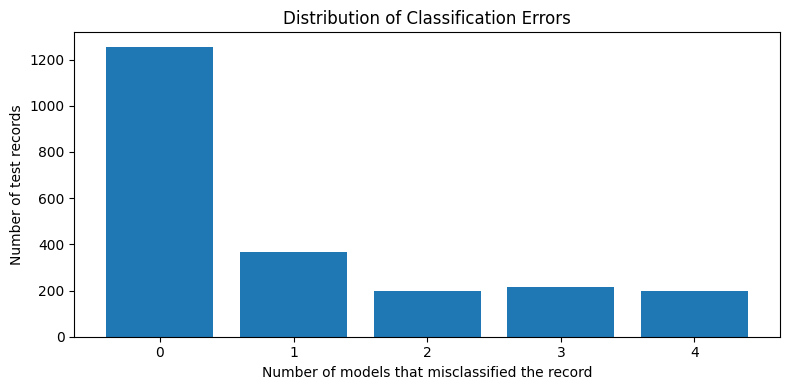

In [ ]:
# PREPARE ERROR ANALYSIS DATA
error_analysis_df = pd.DataFrame({
    "event_name": (
        processed_dataframes["test"]["event_name"].to_numpy()
    ),
    "tweet_id": (
        processed_dataframes["test"]["tweet_id"].astype(str).to_numpy()
    ),
    "image_id": (
        processed_dataframes["test"]["image_id"].astype(str).to_numpy()
    ),
    "text": (
        processed_dataframes["test"]["model_text"].to_numpy()
    ),
    "true_label": [
        ID_TO_LABEL[label] for label in y_test
    ]
})
# ERROR SUMMARY FOR EACH MODEL
error_summary = []
for model_name, predictions in test_predictions.items():
    errors = predictions != y_test
    missed_informative = np.sum(
        (y_test == 0) & (predictions == 1)
    )
    incorrectly_informative = np.sum(
        (y_test == 1) & (predictions == 0)
    )
    error_summary.append({
        "Model": model_name,
        "Correct predictions": int((~errors).sum()),
        "Incorrect predictions": int(errors.sum()),
        "Error rate (%)": round(errors.mean() * 100, 2),
        "Informative predicted as not informative": int(
            missed_informative
        ),
        "Not informative predicted as informative": int(
            incorrectly_informative
        )
    })
error_summary_df = pd.DataFrame(error_summary)
print("CLASSIFICATION ERROR SUMMARY")
display(error_summary_df)
# COMPARE ERRORS ACROSS ALL FOUR MODELS
error_indicator_df = pd.DataFrame({
    model_name: (
        predictions != y_test
    )
    for model_name, predictions in test_predictions.items()
})
error_analysis_df["Number of models incorrect"] = (
    error_indicator_df.sum(axis=1)
)
error_distribution_df = (
    error_analysis_df["Number of models incorrect"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of models incorrect")
    .reset_index(name="Test records")
)
print("\nERROR OVERLAP ACROSS MODELS")
display(error_distribution_df)
# Number of records misclassified by every model
all_models_wrong = (
    error_analysis_df["Number of models incorrect"] == 4
).sum()
print(
    "\nRecords misclassified by all four models:",
    int(all_models_wrong)
)
# VISUALISE ERROR OVERLAP
plt.figure(figsize=(8, 4))
plt.bar(
    error_distribution_df["Number of models incorrect"],
    error_distribution_df["Test records"]
)
plt.xlabel("Number of models that misclassified the record")
plt.ylabel("Number of test records")
plt.title("Distribution of Classification Errors")
plt.xticks([0, 1, 2, 3, 4])
plt.tight_layout()
plt.show()

In [ ]:
# INSPECT HIGH-CONFIDENCE LATE-FUSION ERRORS
late_predictions = test_predictions["Late fusion"]
late_probabilities = test_probabilities["Late fusion"]
late_error_mask = (
    late_predictions != y_test
)
late_errors_df = error_analysis_df.loc[
    late_error_mask
].copy()
late_errors_df["predicted_label"] = [
    ID_TO_LABEL[label]
    for label in late_predictions[late_error_mask]
]
late_errors_df["confidence"] = (
    late_probabilities[late_error_mask]
    .max(axis=1)
)
late_errors_df["informative_probability"] = (
    late_probabilities[late_error_mask, 0]
)
late_errors_df["not_informative_probability"] = (
    late_probabilities[late_error_mask, 1]
)
# Identify type of misclassification
late_errors_df["error_type"] = np.where(
    late_errors_df["true_label"] == "informative",
    "Missed informative post",
    "Not informative predicted as informative"
)
# Display the most confident incorrect predictions
high_confidence_errors = (
    late_errors_df
    .sort_values("confidence", ascending=False)
    .head(10)
)
print("HIGH-CONFIDENCE LATE-FUSION ERRORS")
display(
    high_confidence_errors[
        [
            "event_name",
            "text",
            "true_label",
            "predicted_label",
            "error_type",
            "confidence",
            "informative_probability",
            "not_informative_probability"
        ]
    ].round(4)
)
print("\nTOTAL LATE-FUSION ERRORS:", len(late_errors_df))

HIGH-CONFIDENCE LATE-FUSION ERRORS


,event_name,text,true_label,predicted_label,error_type,confidence,informative_probability,not_informative_probability
823,hurricane_maria,RT @MikeFirstAlert: 11 pm advisory is in for H...,not_informative,informative,Not informative predicted as informative,0.9482,0.9482,0.0518
845,california_wildfires,"California wildfires: ""Like somebody dropped a...",not_informative,informative,Not informative predicted as informative,0.9240,0.9240,0.0760
1709,hurricane_maria,Describing our week in three words: Fuerza Pue...,informative,not_informative,Missed informative post,0.8980,0.1020,0.8980
636,hurricane_irma,#IRMA NFL : Greg Olsen suffers broken foot: ht...,informative,not_informative,Missed informative post,0.8922,0.1078,0.8922
1609,hurricane_irma,Live Irma Update on LashanaMarie Beauty | Blac...,informative,not_informative,Missed informative post,0.8906,0.1094,0.8906
1585,hurricane_irma,Hurricane Irma may have taken my power and wat...,informative,not_informative,Missed informative post,0.8781,0.1219,0.8781
2164,hurricane_maria,Puerto Rico Has Just One Fully Operational Hos...,not_informative,informative,Not informative predicted as informative,0.8779,0.8779,0.1221
903,hurricane_maria,Reds the #HurricaneMaria rescue cat is super f...,informative,not_informative,Missed informative post,0.8766,0.1234,0.8766
1742,hurricane_harvey,"Looks like a small tornado over Wolverhampton,...",not_informative,informative,Not informative predicted as informative,0.8760,0.8760,0.1240
924,hurricane_harvey,Harvey knocked out almost one-quarter of US re...,informative,not_informative,Missed informative post,0.8725,0.1275,0.8725



TOTAL LATE-FUSION ERRORS: 517


## Visual Inspection of Misclassified Images


Disaster event: hurricane_maria
True label: not_informative
Predicted label: informative
Confidence: 0.9482
Text: RT @MikeFirstAlert: 11 pm advisory is in for Hurricane #Maria. Forecast to be well east of JAX Sunday evening. https://t.co/KXJE9LG9C8


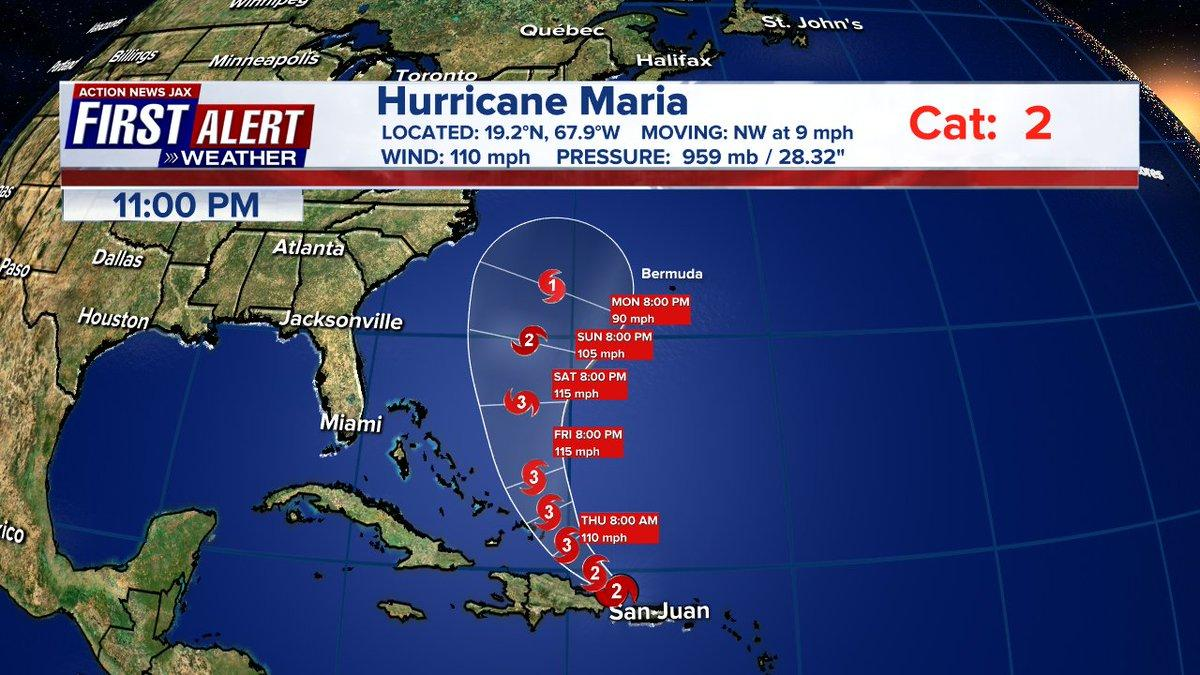


Disaster event: california_wildfires
True label: not_informative
Predicted label: informative
Confidence: 0.924
Text: California wildfires: "Like somebody dropped a bomb on our lives" https://t.co/Gpw1c8Iq41 https://t.co/Yz4z5FYTAK


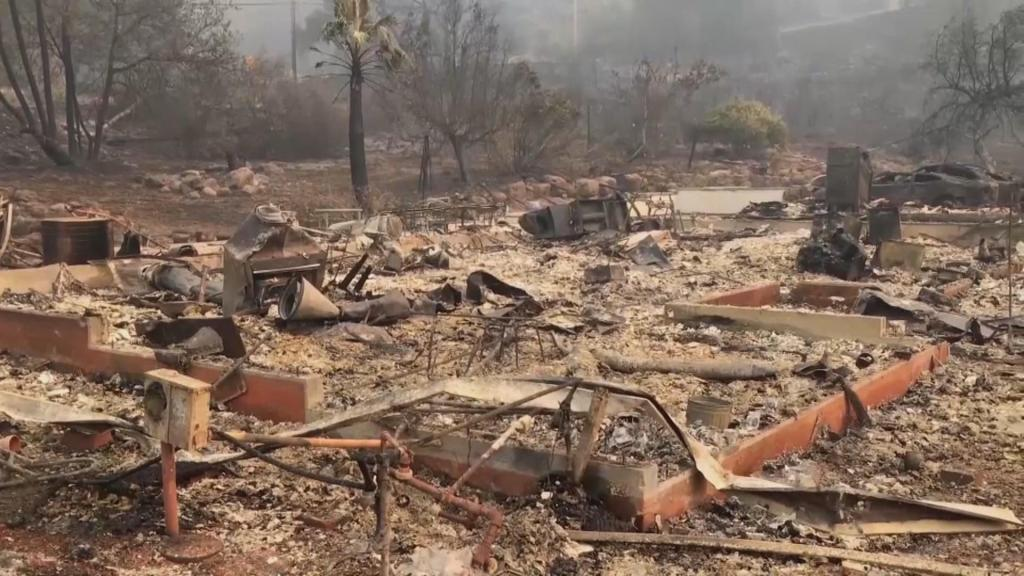


Disaster event: hurricane_maria
True label: informative
Predicted label: not_informative
Confidence: 0.898
Text: Describing our week in three words: Fuerza Puerto Rico @Audi Sunday Recap ➡️ https://t.co/cOBUCVRxMG https://t.co/T9FBwDau4g


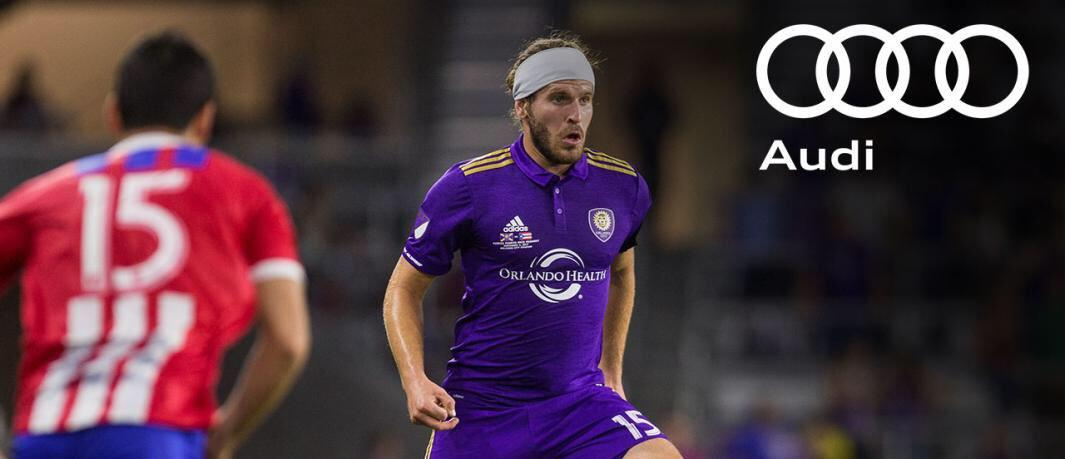


Disaster event: hurricane_irma
True label: informative
Predicted label: not_informative
Confidence: 0.8922
Text: #IRMA NFL : Greg Olsen suffers broken foot: https://t.co/f26iX6Q2Ov https://t.co/Or1c08bS2R (via Twitter… https://t.co/y2YJnimatr


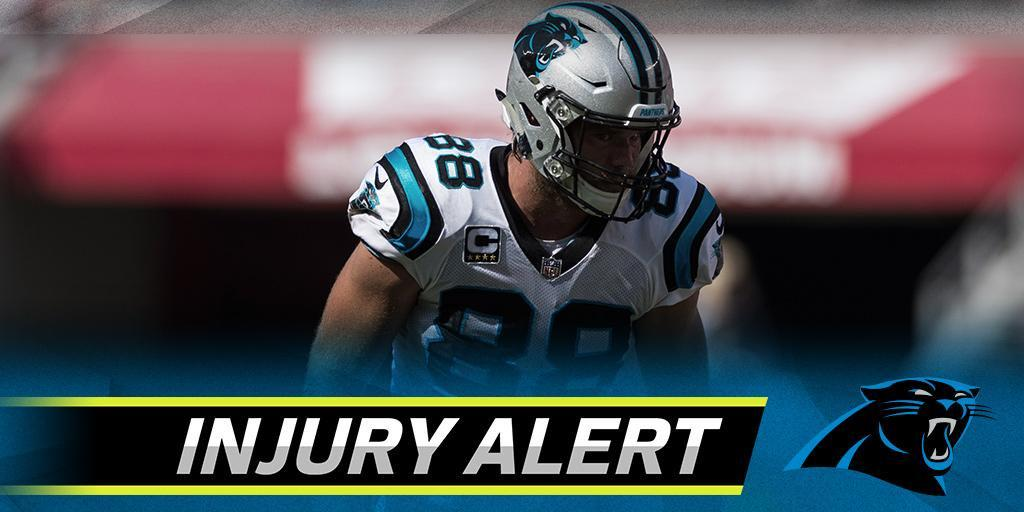

In [ ]:
# Visual inspection of selected late-fusion errors
for idx, row in high_confidence_errors.head(4).iterrows():
    image_path = (
        DATASET_SNAPSHOT_DIR
        / processed_dataframes["test"].loc[idx, "image_path"]
    )
    print("\nDisaster event:", row["event_name"])
    print("True label:", row["true_label"])
    print("Predicted label:", row["predicted_label"])
    print("Confidence:", round(row["confidence"], 4))
    print("Text:", row["text"])
    with Image.open(image_path) as img:
        display(img.convert("RGB"))

## Final Results Summary and Saving Project Outputs

In [ ]:
# Final test performance summary
print("FINAL TEST PERFORMANCE")
final_results_summary = (
    final_test_comparison[
        [
            "Model",
            "accuracy",
            "precision",
            "recall",
            "macro_f1",
            "auroc"
        ]
    ]
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)
display(final_results_summary.round(4))
print("\nSELECTED MODEL CONFIGURATIONS")
display(
    selected_validation_results
    .drop(columns=["loss"], errors="ignore")
    .round(4)
)
print("\nSELECTED LATE FUSION WEIGHTS")
print("Text:", BEST_TEXT_WEIGHT)
print("Image:", BEST_IMAGE_WEIGHT)

FINAL TEST PERFORMANCE


,Model,accuracy,precision,recall,macro_f1,auroc
0,Late fusion,0.7689,0.7564,0.7598,0.7579,0.8527
1,Early fusion,0.7631,0.7520,0.7604,0.7547,0.8534
2,Image-only,0.7389,0.7306,0.7412,0.7322,0.8042
3,Text-only,0.7403,0.7262,0.7273,0.7267,0.7972



SELECTED MODEL CONFIGURATIONS


,Model,Selected version,accuracy,precision,recall,macro_f1,auroc
0,Text-only,Regularised,0.7318,0.7149,0.7216,0.7174,0.7792
1,Image-only,Regularised,0.7349,0.7208,0.7315,0.7236,0.7999
2,Early fusion,Regularised,0.7747,0.7596,0.7683,0.7629,0.8535
3,Late fusion,Baseline,0.7747,0.7589,0.7643,0.7612,0.8422



SELECTED LATE FUSION WEIGHTS
Text: 0.45
Image: 0.55


In [ ]:
# Save final selected model weights
def cpu_state_dict(model):
    return {
        key: value.detach().cpu()
        for key, value in model.state_dict().items()
    }
final_selected_models = {
    "text_only": {
        "version": "regularised",
        "input_dim": 768,
        "hidden_dim": 128,
        "dropout": 0.5,
        "state_dict": cpu_state_dict(text_model_reg)
    },
    "image_only": {
        "version": "regularised",
        "input_dim": 1280,
        "hidden_dim": 128,
        "dropout": 0.5,
        "state_dict": cpu_state_dict(image_model_reg)
    },
    "early_fusion": {
        "version": "regularised",
        "input_dim": 2048,
        "hidden_dim": 128,
        "dropout": 0.5,
        "state_dict": cpu_state_dict(early_fusion_model_reg)
    },
    "late_fusion": {
        "version": "baseline",
        "text_weight": BEST_TEXT_WEIGHT,
        "image_weight": BEST_IMAGE_WEIGHT,
        "text_model_state_dict": cpu_state_dict(text_model),
        "image_model_state_dict": cpu_state_dict(image_model)
    }
}
torch.save(
    final_selected_models,
    CHECKPOINT_DIR / "final_selected_models.pt"
)
print("Final selected models saved successfully.")

Final selected models saved successfully.
